# Credit Card Fraud Detection with Bagging, Boosting and Stacking

**Course assignment — Ensemble Learning, Project 1 (Classification)**

This notebook builds a complete, leakage-safe machine-learning workflow for detecting fraudulent card transactions. Four single-model baselines (Decision Tree, Logistic Regression, SVM, KNN) are compared with three ensemble families:

| Family | Model used here | Core idea |
|---|---|---|
| Bagging | Random Forest | many de-correlated trees trained on bootstrap samples, averaged |
| Boosting | Histogram-based Gradient Boosting | shallow trees added one after another, each fixing the previous errors |
| Stacking | `StackingClassifier` | a meta-model learns how to combine the out-of-fold predictions of diverse base models |

**How the notebook is organised**

1. Title and introduction · 2. Business problem and objectives · 3. Dataset overview · 4. Libraries · 5. Loading and exploration · 6. EDA · 7. Preprocessing and feature engineering · 8. Train / validation / test split · 9. Baseline models · 10. Bagging · 11. Boosting · 12. Stacking · 13. Hyperparameter-tuning summary · 14. Evaluation and comparison · 15. Visualisations and feature importance · 16. Discussion · 17. Conclusion · 18. References

## 2. Business Problem and Project Objectives

A card issuer must decide, within milliseconds, whether a transaction looks fraudulent. Two kinds of mistakes are possible:

* **False negative (missed fraud)** — the money is lost, the customer is upset and the bank usually refunds the loss.
* **False positive (false alarm)** — a genuine purchase is blocked or sent to an analyst. Each alert costs review time and annoys a legitimate customer.

Fraud is extremely rare, so a model that predicts "legitimate" for everything would look >99.8 % *accurate* while catching nothing. The objectives are therefore:

1. Build models that **rank** transactions so that fraud appears near the top (measured with **Average Precision / PR-AUC** and ROC-AUC).
2. Choose an **operating threshold** that catches most fraud (high **recall**) without flooding analysts with false alerts (acceptable **precision**).
3. Compare single models with Bagging, Boosting and Stacking under one fair protocol, and recommend a model for deployment.

## 3. Dataset Overview

* **Source:** [Credit Card Fraud Detection — Kaggle (mlg-ulb/creditcardfraud)](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud), collected by Worldline and the Machine Learning Group of ULB.
* **Content:** transactions made by European cardholders over two days in September 2013.
* **Features:**
  * `V1` … `V28` — principal components obtained with PCA. The original features are confidential, so these components cannot be interpreted directly.
  * `Time` — seconds elapsed since the first transaction in the file.
  * `Amount` — transaction amount.
* **Target:** `Class` — `1` = fraud, `0` = legitimate.

Because `V1`–`V28` are already the output of PCA (centred, decorrelated components), this notebook **does not transform them further** except for standard scaling inside the pipelines of scale-sensitive models (explained in Section 7).

## 4. Import Libraries

`imbalanced-learn` is the only library that may not be pre-installed; the next cell installs it automatically when missing. Everything else ships with Anaconda and Google Colab.

In [1]:
# Install imbalanced-learn only if it is missing (needed for SMOTE / undersampling inside pipelines)
import importlib.util, subprocess, sys
if importlib.util.find_spec("imblearn") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"])

In [2]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import imblearn

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     RandomizedSearchCV, cross_validate)
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier,
                              StackingClassifier)
from sklearn.inspection import permutation_importance
from sklearn.metrics import (precision_score, recall_score, f1_score, fbeta_score, accuracy_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             precision_recall_curve, roc_curve, ConfusionMatrixDisplay)
from imblearn.pipeline import Pipeline            # sampler-aware pipeline (samplers run only during fit)
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.dpi"] = 110

for lib in (np, pd, sklearn, imblearn, sns):
    print(f"{lib.__name__:<12} {lib.__version__}")
print(f"{'matplotlib':<12} {plt.matplotlib.__version__}")
print(f"{'python':<12} {sys.version.split()[0]}")

numpy        2.5.3
pandas       3.0.5
sklearn      1.9.1
imblearn     0.14.2
seaborn      0.13.2
matplotlib   3.11.2
python       3.13.17


## 5. Data Loading and Exploration

### 5.1 Getting the CSV file

The notebook looks for `creditcard.csv` in this order:

1. The current folder, a `data/` sub-folder, `/content` (Colab) or `/kaggle/input/creditcardfraud` (Kaggle Notebooks).
2. **Optional Kaggle download** — set `USE_KAGGLEHUB = True`. This uses the `kagglehub` package. Never paste your API key into the notebook; instead put `kaggle.json` in `~/.kaggle/` (local) or add `KAGGLE_USERNAME` / `KAGGLE_KEY` to **Colab → Secrets** / environment variables.
3. **Google Colab upload dialog** — if nothing is found, Colab will open a file picker. The file is ~150 MB, so uploading it to Google Drive first and copying it to `/content` is usually faster.

If none of these work, the cell stops with a clear error message telling you where to put the file.

In [3]:
DATA_FILE = "creditcard.csv"
KAGGLE_SLUG = "mlg-ulb/creditcardfraud"
USE_KAGGLEHUB = False          # switch to True to download with kagglehub (needs Kaggle credentials)


def locate_csv(filename: str, slug: str, try_kagglehub: bool = False) -> Path:
    """Return the path of the dataset CSV, trying local folders, kagglehub and Colab upload."""
    candidates = [Path.cwd(), Path.cwd() / "data", Path("/content"), Path("/content/data"),
                  Path("/kaggle/input") / slug.split("/")[1], Path.home() / "data"]
    for folder in candidates:
        if (folder / filename).is_file():
            return folder / filename

    if try_kagglehub:
        import kagglehub
        download_dir = Path(kagglehub.dataset_download(slug))
        matches = sorted(download_dir.rglob(filename))
        if matches:
            return matches[0]

    try:                                   # only works inside Google Colab
        from google.colab import files
        print(f"Please choose '{filename}' in the upload dialog ...")
        uploaded = files.upload()
        if filename in uploaded:
            return Path(filename)
    except ImportError:
        pass

    raise FileNotFoundError(
        f"'{filename}' not found. Download it from https://www.kaggle.com/datasets/{slug} "
        f"and place it next to this notebook (or in a 'data/' folder), then re-run this cell.")


csv_path = locate_csv(DATA_FILE, KAGGLE_SLUG, USE_KAGGLEHUB)
raw = pd.read_csv(csv_path)
print(f"Loaded {csv_path}  ->  {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

Loaded /root/run/creditcard.csv  ->  284,807 rows x 31 columns


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
print("Column names:", list(raw.columns), "\n")
raw.info()

Column names: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class'] 

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non

In [5]:
# Descriptive statistics (transposed so that every feature is one row)
raw.describe().T.style.format("{:.3f}")

,count,mean,std,min,25%,50%,75%,max
Time,284807.000,94813.860,47488.146,0.000,54201.500,84692.000,139320.500,172792.000
V1,284807.000,0.000,1.959,-56.408,-0.920,0.018,1.316,2.455
V2,284807.000,-0.000,1.651,-72.716,-0.599,0.065,0.804,22.058
V3,284807.000,-0.000,1.516,-48.326,-0.890,0.180,1.027,9.383
V4,284807.000,0.000,1.416,-5.683,-0.849,-0.020,0.743,16.875
V5,284807.000,0.000,1.380,-113.743,-0.692,-0.054,0.612,34.802
V6,284807.000,0.000,1.332,-26.161,-0.768,-0.274,0.399,73.302
V7,284807.000,-0.000,1.237,-43.557,-0.554,0.040,0.570,120.589
V8,284807.000,0.000,1.194,-73.217,-0.209,0.022,0.327,20.007
V9,284807.000,-0.000,1.099,-13.434,-0.643,-0.051,0.597,15.595


In [6]:
missing = raw.isna().sum()
print(f"Total missing values: {missing.sum()}")
print("Columns with missing values:", list(missing[missing > 0].index) or "none")

Total missing values: 0
Columns with missing values: none


### 5.2 Duplicate rows

Exact duplicates can be genuine (e.g. two identical small payments) or artefacts of data extraction. For **model evaluation** they are dangerous: if one copy lands in the training set and the other in the test set, the model is tested on a transaction it has already memorised, which inflates the scores. We inspect them before deciding.

In [7]:
dup_mask = raw.duplicated(keep="first")
n_dup = int(dup_mask.sum())
print(f"Exact duplicate rows: {n_dup:,} ({n_dup / len(raw):.2%} of all rows)")
print("Class of the duplicated rows:")
print(raw.loc[dup_mask, "Class"].value_counts().rename({0: "legitimate", 1: "fraud"}).to_string())

Exact duplicate rows: 1,081 (0.38% of all rows)
Class of the duplicated rows:
Class
legitimate    1062
fraud           19


**Decision:** the duplicates are a small fraction of the data and every feature (including the exact second in `Time`) is identical, so they add no new information. We keep the first occurrence and drop the copies so that no transaction can appear on both sides of the train/test boundary.

In [8]:
df = raw.drop_duplicates(keep="first").reset_index(drop=True)
print(f"Rows after removing duplicates: {len(df):,}")

Rows after removing duplicates: 283,726


### 5.3 Target distribution

,count,percent
Class,,
Legitimate (0),"283,253",99.833%
Fraud (1),473,0.167%


Imbalance ratio: about 1 fraud for every 599 legitimate transactions


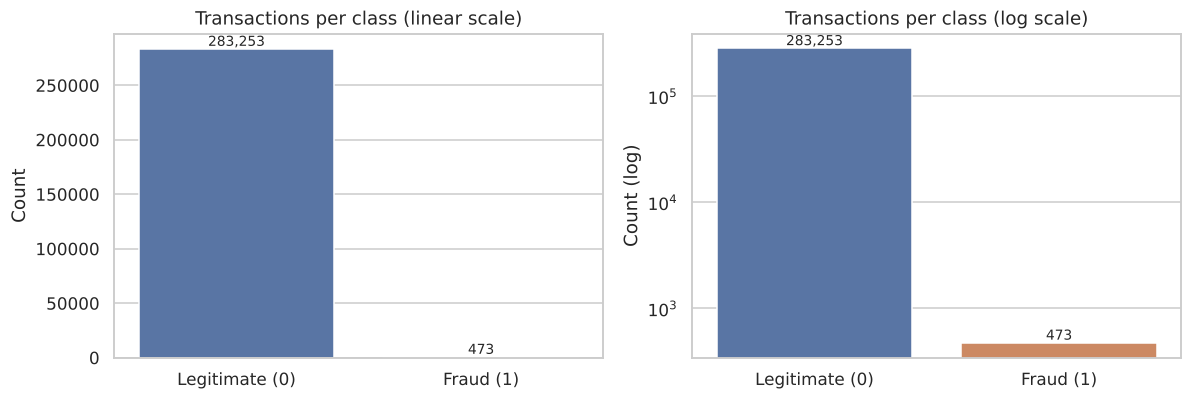

In [9]:
class_table = (df["Class"].value_counts()
               .rename(index={0: "Legitimate (0)", 1: "Fraud (1)"})
               .to_frame("count"))
class_table["percent"] = 100 * class_table["count"] / class_table["count"].sum()
display(class_table.style.format({"count": "{:,}", "percent": "{:.3f}%"}))

imbalance_ratio = class_table["count"].iloc[0] / class_table["count"].iloc[1]
print(f"Imbalance ratio: about 1 fraud for every {imbalance_ratio:.0f} legitimate transactions")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.barplot(x=class_table.index, y=class_table["count"], ax=axes[0], hue=class_table.index, legend=False)
axes[0].set(title="Transactions per class (linear scale)", xlabel="", ylabel="Count")
sns.barplot(x=class_table.index, y=class_table["count"], ax=axes[1], hue=class_table.index, legend=False)
axes[1].set_yscale("log")
axes[1].set(title="Transactions per class (log scale)", xlabel="", ylabel="Count (log)")
for ax in axes:
    for p in ax.patches:
        ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

**Why the imbalance matters**

* Fraud is well under 1 % of the data. A "model" that always answers *legitimate* reaches >99.8 % accuracy and is useless — so **accuracy is not used for model selection**.
* Most learning algorithms minimise overall error, so they are naturally pulled toward the majority class. We counter this with class weighting or resampling (Section 8.1) and by **tuning the decision threshold** on the validation set.
* With only a few hundred fraud cases, every split must be **stratified** so that train, validation and test each keep the same fraud rate, and results on the small number of test frauds will carry noticeable uncertainty.

## 6. Exploratory Data Analysis (EDA)

### 6.1 Amount and time of day

`Time` counts seconds from the start of the two-day window. Converting it to **hour of day** reveals the daily cycle of card activity, which is more meaningful than the raw counter.

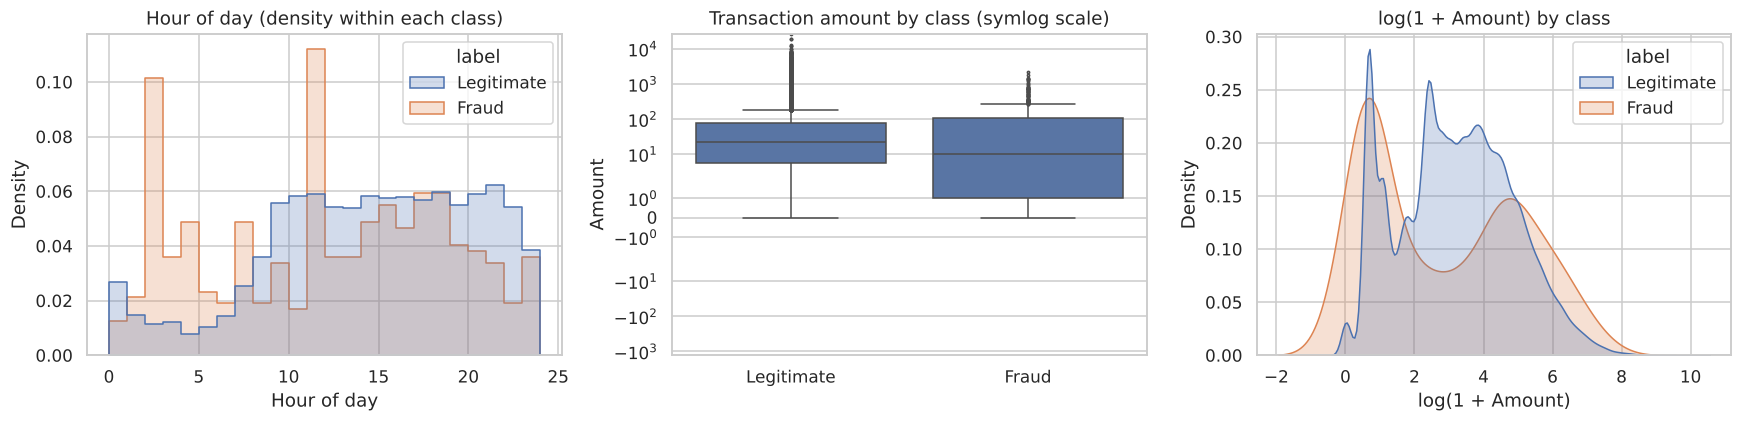

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
Fraud,473.00,123.87,260.21,0.00,1.00,9.82,105.89,2125.87
Legitimate,283253.00,88.41,250.38,0.00,5.67,22.00,77.46,25691.16


In [10]:
eda = df.assign(hour=(df["Time"] / 3600) % 24,
                label=df["Class"].map({0: "Legitimate", 1: "Fraud"}))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(data=eda, x="hour", hue="label", bins=24, stat="density", common_norm=False,
             element="step", ax=axes[0])
axes[0].set(title="Hour of day (density within each class)", xlabel="Hour of day")

sns.boxplot(data=eda, x="label", y="Amount", ax=axes[1], showfliers=True, fliersize=1.5)
axes[1].set_yscale("symlog")
axes[1].set(title="Transaction amount by class (symlog scale)", xlabel="")

sns.kdeplot(data=eda, x=np.log1p(eda["Amount"]), hue="label", common_norm=False, fill=True, ax=axes[2])
axes[2].set(title="log(1 + Amount) by class", xlabel="log(1 + Amount)")
plt.tight_layout()
plt.show()

display(eda.groupby("label")["Amount"].describe().style.format("{:.2f}"))

Observations (from the plots above):

* Legitimate activity follows a clear day/night rhythm, while fraud is spread more evenly across the night hours, so the fraud **share** is higher at night. Hour of day is therefore a useful engineered feature.
* `Amount` is extremely right-skewed. Most frauds are small amounts, i.e. a large amount on its own is not a reliable fraud signal. A `log(1 + Amount)` transform makes the distribution far more symmetric, which helps linear and distance-based models.

### 6.2 Which PCA components separate the classes?

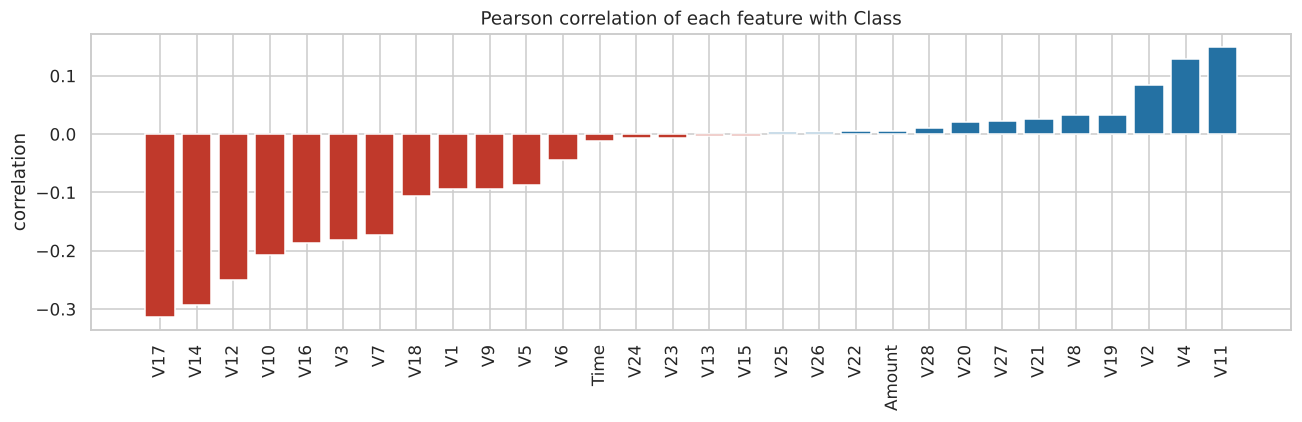

Most strongly correlated features: ['V17', 'V14', 'V12', 'V10', 'V16', 'V3']


In [11]:
v_cols = [f"V{i}" for i in range(1, 29)]
corr_with_target = df[v_cols + ["Amount", "Time", "Class"]].corr()["Class"].drop("Class").sort_values()

fig, ax = plt.subplots(figsize=(12, 4))
colors = np.where(corr_with_target < 0, "#c0392b", "#2471a3")
ax.bar(corr_with_target.index, corr_with_target.values, color=colors)
ax.set(title="Pearson correlation of each feature with Class", ylabel="correlation")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

strongest = corr_with_target.abs().sort_values(ascending=False).index[:6].tolist()
print("Most strongly correlated features:", strongest)

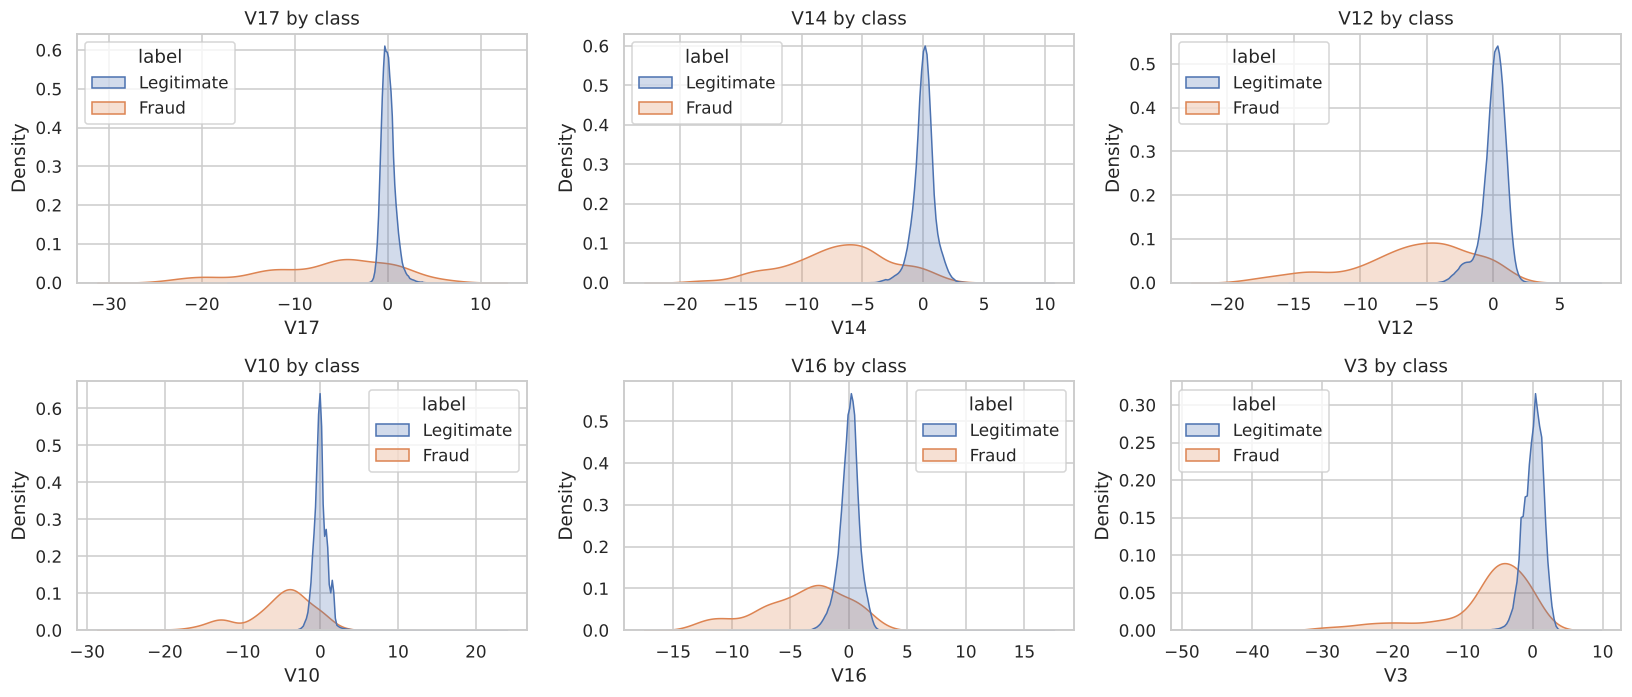

In [12]:
# Class-conditional distributions of the six most informative components
fig, axes = plt.subplots(2, 3, figsize=(15, 6.5))
for ax, col in zip(axes.ravel(), strongest):
    sns.kdeplot(data=eda, x=col, hue="label", common_norm=False, fill=True, ax=ax, warn_singular=False)
    ax.set_title(f"{col} by class")
plt.tight_layout()
plt.show()

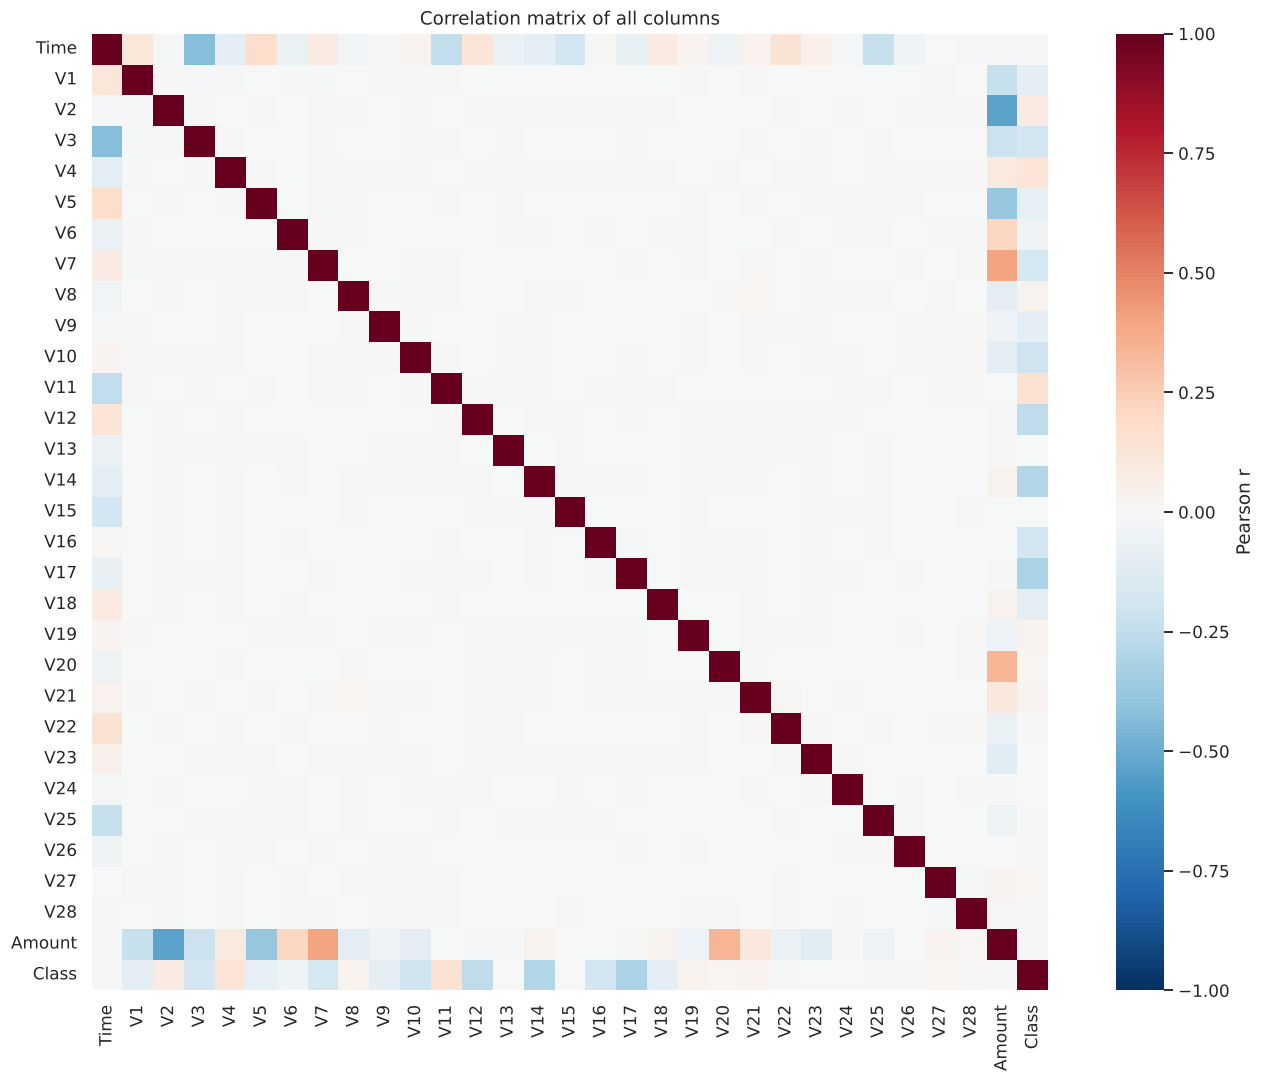

In [13]:
# Correlation heat-map. PCA components are uncorrelated with each other by construction,
# so only Time and Amount should show visible correlations with the V-features.
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(df.corr(), cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax,
            cbar_kws={"label": "Pearson r"}, square=True)
ax.set_title("Correlation matrix of all columns")
plt.tight_layout()
plt.show()

The heat-map confirms that the `V` components are (almost) uncorrelated with each other — exactly what PCA produces — so multicollinearity is not a concern. Several components (e.g. `V14`, `V17`, `V12`, `V10`) shift strongly for fraud, which suggests that even simple models will find a useful signal.

### 6.3 Outliers

In [14]:
def iqr_outlier_share(frame: pd.DataFrame, columns, k: float = 1.5) -> pd.DataFrame:
    """Share of values outside [Q1 - k*IQR, Q3 + k*IQR] overall and among frauds."""
    rows = []
    for col in columns:
        q1, q3 = frame[col].quantile([0.25, 0.75])
        lo, hi = q1 - k * (q3 - q1), q3 + k * (q3 - q1)
        out = (frame[col] < lo) | (frame[col] > hi)
        rows.append({"feature": col,
                     "outliers_all_%": 100 * out.mean(),
                     "outliers_in_fraud_%": 100 * out[frame["Class"] == 1].mean()})
    return pd.DataFrame(rows).set_index("feature").sort_values("outliers_in_fraud_%", ascending=False)

outlier_report = iqr_outlier_share(df, v_cols + ["Amount"])
display(outlier_report.head(10).style.format("{:.1f}"))

,outliers_all_%,outliers_in_fraud_%
feature,,
V14,5.0,86.9
V12,5.4,82.5
V10,3.3,80.3
V17,2.6,80.1
V16,2.9,70.4
V27,13.7,69.1
V4,3.9,63.4
V3,1.2,61.9
V7,3.1,59.8


**Decision on outliers:** for many components the large majority of fraudulent transactions fall *outside* the IQR fences. In fraud detection unusual behaviour **is the signal**, so removing "outliers" would delete a large part of the minority class. We keep all rows. Robustness is handled instead by (a) the log transform of `Amount`, and (b) tree-based models, which are insensitive to extreme values.

## 7. Data Preprocessing and Feature Engineering

### 7.1 Feature engineering

| New feature | Formula | Reason |
|---|---|---|
| `hour_sin`, `hour_cos` | sine/cosine of hour of day | captures the daily cycle; the cyclic encoding makes 23:00 close to 00:00 |
| `log_amount` | `log(1 + Amount)` | removes the extreme skew of `Amount` |

The raw `Time` counter is dropped because its absolute value only says *when within this particular 48-hour file* the payment happened, which would not generalise to future data. `Amount` is replaced by `log_amount` (the transform is monotonic, so tree models lose nothing).

These are **row-by-row, stateless** transformations: nothing is estimated from the data, so applying them before the split cannot leak information. Everything that *is* learned from data (scalers, resamplers, models) is fitted later, inside pipelines, on training data only.

In [15]:
def add_engineered_features(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    hour = (out["Time"] / 3600.0) % 24
    out["hour_sin"] = np.sin(2 * np.pi * hour / 24)
    out["hour_cos"] = np.cos(2 * np.pi * hour / 24)
    out["log_amount"] = np.log1p(out["Amount"])
    return out.drop(columns=["Time", "Amount"])

X_all = add_engineered_features(df.drop(columns="Class"))
y_all = df["Class"].to_numpy()
FEATURES = X_all.columns.tolist()
print(f"{len(FEATURES)} model features:", FEATURES[:4], "...", FEATURES[-3:])

31 model features: ['V1', 'V2', 'V3', 'V4'] ... ['hour_sin', 'hour_cos', 'log_amount']


### 7.2 Scaling with a `ColumnTransformer` (fitted inside each pipeline)

* **Logistic Regression, SVM and KNN** depend on distances or on the size of coefficients, so features must be on comparable scales. The PCA components do *not* share one variance (for example `V1` varies far more than `V28`), so `StandardScaler` is applied to them and to `log_amount`. The cyclic hour features already lie in [-1, 1] and are passed through unchanged.
* **Tree-based models** split on thresholds and are unaffected by monotonic rescaling, so they receive the features as they are.

Because the scaler sits *inside* the pipeline, during cross-validation it is re-fitted on each training fold only, and the validation/test sets are only ever transformed with statistics learned from training data.

In [16]:
scaled_cols = [c for c in FEATURES if c not in ("hour_sin", "hour_cos")]

def make_scaler() -> ColumnTransformer:
    """Fresh, unfitted preprocessing step for scale-sensitive models."""
    return ColumnTransformer([("standardise", StandardScaler(), scaled_cols)],
                             remainder="passthrough")

CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
PRIMARY_SCORING = "average_precision"
print("Cross-validation:", CV)

Cross-validation: StratifiedKFold(n_splits=3, random_state=42, shuffle=True)


## 8. Train / Validation / Test Split

* **60 % training** — model fitting and cross-validated hyperparameter search.
* **20 % validation** — comparing tuned models and choosing each model's decision threshold.
* **20 % test** — touched **once**, at the very end, to report final performance.

All splits are **stratified** on `Class` so the fraud rate is identical in each part, and the random seed is fixed for reproducibility.

In [17]:
X_temp, X_test, y_temp, y_test = train_test_split(X_all, y_all, test_size=0.20,
                                                  stratify=y_all, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25,   # 0.25 * 0.8 = 0.2
                                                  stratify=y_temp, random_state=SEED)

split_summary = pd.DataFrame({
    "rows": [len(y_train), len(y_val), len(y_test)],
    "frauds": [y_train.sum(), y_val.sum(), y_test.sum()],
}, index=["train", "validation", "test"])
split_summary["fraud_rate_%"] = 100 * split_summary["frauds"] / split_summary["rows"]
split_summary.style.format({"rows": "{:,}", "fraud_rate_%": "{:.3f}"})

,rows,frauds,fraud_rate_%
train,"170,235",284,0.167
validation,"56,745",94,0.166
test,"56,746",95,0.167


### 8.1 Handling the class imbalance — a controlled experiment (training data only)

Three common strategies are compared using the same Logistic Regression and the same cross-validation folds:

| Strategy | What it does | Where it is applied |
|---|---|---|
| **Class weighting** | errors on fraud cost ~`n_legit / n_fraud` times more in the loss | inside the model, no data is changed |
| **SMOTE** | creates synthetic frauds by interpolating between a fraud and its fraud neighbours | training folds only |
| **Random undersampling** | discards legitimate rows at random until a target ratio is reached | training folds only |

The `imblearn` `Pipeline` guarantees that samplers act **only during `fit`**. When the pipeline predicts on a validation fold, the validation set, or the test set, no resampling happens, so all evaluation data keeps its real class distribution.

In [18]:
def fraud_scores(model, X) -> np.ndarray:
    """Continuous fraud score: probability if available, otherwise the SVM decision value."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


def lr_pipeline(balance_step="passthrough", class_weight=None) -> Pipeline:
    return Pipeline([("scale", make_scaler()),
                     ("balance", balance_step),
                     ("model", LogisticRegression(max_iter=2000, class_weight=class_weight))])

imbalance_options = {
    "No adjustment": lr_pipeline(),
    "Class weighting": lr_pipeline(class_weight="balanced"),
    "SMOTE (fraud -> 10% of legit)": lr_pipeline(SMOTE(sampling_strategy=0.1, random_state=SEED)),
    "Undersampling (fraud = 2% of legit)": lr_pipeline(RandomUnderSampler(sampling_strategy=0.02,
                                                                         random_state=SEED)),
}

rows = []
for label, pipe in imbalance_options.items():
    cv_res = cross_validate(pipe, X_train, y_train, cv=CV, n_jobs=-1,
                            scoring={"AP": "average_precision", "recall": "recall", "precision": "precision"})
    pipe.fit(X_train, y_train)
    val_pred = pipe.predict(X_val)
    rows.append({"strategy": label,
                 "CV AP": cv_res["test_AP"].mean(),
                 "CV recall@0.5": cv_res["test_recall"].mean(),
                 "CV precision@0.5": cv_res["test_precision"].mean(),
                 "val AP": average_precision_score(y_val, fraud_scores(pipe, X_val)),
                 "val recall@0.5": recall_score(y_val, val_pred),
                 "val precision@0.5": precision_score(y_val, val_pred, zero_division=0)})

imbalance_results = pd.DataFrame(rows).set_index("strategy")
imbalance_results.style.format("{:.3f}").background_gradient(cmap="Greens", axis=0)

,CV AP,CV recall@0.5,CV precision@0.5,val AP,val recall@0.5,val precision@0.5
strategy,,,,,,
No adjustment,0.737,0.591,0.828,0.801,0.691,0.878
Class weighting,0.729,0.890,0.050,0.790,0.915,0.053
SMOTE (fraud -> 10% of legit),0.733,0.852,0.373,0.803,0.894,0.431
Undersampling (fraud = 2% of legit),0.724,0.813,0.621,0.801,0.862,0.643


**How to read this table.** The imbalance strategies mainly *move the default 0.5 threshold*: they raise recall a lot and pay for it with precision. Average Precision, which looks at the ranking over **all** thresholds, changes much less — and can even drop, because SMOTE and undersampling distort the probability scale. The practical lessons used in the rest of the notebook are:

1. **Class weighting** is kept as a tunable hyperparameter (`class_weight ∈ {None, "balanced"}`) wherever the model supports it, and cross-validation decides.
2. **Random undersampling** is used for SVM and KNN, which have no usable class weights (KNN) or are too slow on 170 k rows (SVM). It makes them computationally feasible *and* rebalances the classes.
3. For every model the final **decision threshold is chosen on the validation set** (Section 9.1), which is the most direct way to control the recall/precision trade-off.

## 9. Individual Baseline Models

### 9.1 Shared tuning and bookkeeping helpers

Every model goes through the same steps so the comparison is fair:

1. Hyperparameter search with 3-fold **stratified** CV on the training set, optimising **Average Precision**.
2. The best configuration is automatically refitted on the whole training set (`refit=True`); its fit time is the **training time** reported later (`refit_time_`).
3. Scores on the validation set are used to pick a **decision threshold** that maximises the **F2-score**. F2 weights recall twice as much as precision, reflecting that a missed fraud is usually more expensive than reviewing a false alert.
4. Everything is stored in the `board` dictionary, from which all tables and plots are generated.

In [19]:
board = {}          # model name -> dict with search object, fitted model, CV and validation results


def best_fbeta_threshold(y_true, scores, beta: float = 2.0):
    """Threshold on the score that maximises F-beta (computed on validation data only)."""
    prec, rec, thr = precision_recall_curve(y_true, scores)
    prec, rec = prec[:-1], rec[:-1]                     # last point has no threshold
    fbeta = (1 + beta**2) * prec * rec / np.clip(beta**2 * prec + rec, 1e-12, None)
    best = int(np.nanargmax(fbeta))
    return float(thr[best]), float(fbeta[best])


def register(name, search=None, model=None, fit_seconds=None, cv_scores=None):
    """Store a tuned model, its CV score and its validation behaviour."""
    if search is not None:
        model = search.best_estimator_
        fit_seconds = search.refit_time_
        i = search.best_index_
        cv_mean = search.cv_results_["mean_test_score"][i]
        cv_std = search.cv_results_["std_test_score"][i]
        params = search.best_params_
    else:
        cv_mean, cv_std, params = np.mean(cv_scores), np.std(cv_scores), {}
    val_scores = fraud_scores(model, X_val)
    thr, f2 = best_fbeta_threshold(y_val, val_scores)
    board[name] = dict(model=model, fit_seconds=fit_seconds, cv_ap=cv_mean, cv_ap_std=cv_std,
                       params=params, val_scores=val_scores, threshold=thr,
                       val_ap=average_precision_score(y_val, val_scores),
                       val_roc=roc_auc_score(y_val, val_scores), val_f2=f2)
    print(f"{name:<22} CV AP = {cv_mean:.3f} ± {cv_std:.3f} | val AP = {board[name]['val_ap']:.3f} | "
          f"val ROC-AUC = {board[name]['val_roc']:.3f} | F2-threshold = {thr:.4g} | fit {fit_seconds:.1f}s")
    if params:
        print("   best params:", params)


def run_search(estimator, grid, n_iter=None, n_jobs=-1):
    """GridSearchCV (n_iter=None) or RandomizedSearchCV, always on the training data."""
    common = dict(scoring=PRIMARY_SCORING, cv=CV, n_jobs=n_jobs, refit=True)
    if n_iter is None:
        search = GridSearchCV(estimator, grid, **common)
    else:
        search = RandomizedSearchCV(estimator, grid, n_iter=n_iter, random_state=SEED, **common)
    t0 = time.perf_counter()
    search.fit(X_train, y_train)
    print(f"   search finished in {time.perf_counter() - t0:.0f}s "
          f"({len(search.cv_results_['params'])} configurations x {CV.get_n_splits()} folds)")
    return search

### 9.2 Decision Tree

**Idea.** A decision tree asks a sequence of yes/no questions about single features ("is `V14` < −4.2?") and ends in a leaf that predicts the majority class of the training rows that reached it.

**Why include it.** It is interpretable, needs no scaling, captures non-linear interactions, and — most importantly for this assignment — it is the building block of Random Forest and Gradient Boosting. A single deep tree has **low bias but high variance**, which is exactly the weakness that bagging is designed to fix.

**Tuned hyperparameters:** `max_depth` (tree complexity), `min_samples_leaf` (minimum rows per leaf, smooths predictions), `class_weight`.

In [20]:
dt_search = run_search(
    DecisionTreeClassifier(random_state=SEED),
    {"max_depth": [4, 6, 8, 12],
     "min_samples_leaf": [5, 25],
     "class_weight": [None, "balanced"]})
register("Decision Tree", dt_search)

   search finished in 78s (16 configurations x 3 folds)
Decision Tree          CV AP = 0.737 ± 0.063 | val AP = 0.800 | val ROC-AUC = 0.942 | F2-threshold = 0.5 | fit 5.8s
   best params: {'class_weight': None, 'max_depth': 8, 'min_samples_leaf': 5}


### 9.3 Logistic Regression

**Idea.** Logistic regression combines the features linearly, `z = w·x + b`, and turns `z` into a probability with the sigmoid function. Training minimises log-loss plus an L2 penalty whose strength is `1/C`.

**Why include it.** It is fast, well calibrated and a strong benchmark whenever the classes are roughly linearly separable — which the EDA suggests is partly true for the PCA components. It also provides a smooth, high-bias contrast to the trees.

**Tuned hyperparameters:** `C` (inverse regularisation strength) and `class_weight`.

In [21]:
lr_search = run_search(
    lr_pipeline(),
    {"model__C": [0.01, 0.1, 1.0, 10.0],
     "model__class_weight": [None, "balanced"]})
register("Logistic Regression", lr_search)

   search finished in 4s (8 configurations x 3 folds)
Logistic Regression    CV AP = 0.737 ± 0.038 | val AP = 0.801 | val ROC-AUC = 0.975 | F2-threshold = 0.05216 | fit 0.3s
   best params: {'model__C': 1.0, 'model__class_weight': None}


### 9.4 Support Vector Machine (SVM)

**Idea.** An SVM looks for the boundary with the **largest margin** between the classes. With the RBF kernel the boundary can be curved: `gamma` controls how far the influence of a single training point reaches and `C` controls how strongly margin violations are penalised.

**Why include it.** It is a powerful non-linear, margin-based method that behaves very differently from trees and linear models.

**Computational note.** Kernel SVM training scales roughly quadratically with the number of rows, so fitting it on ~170 k transactions (many times, for cross-validation) is impractical. The pipeline therefore **randomly undersamples the legitimate class inside each training fold** until frauds make up 2 % of the majority class (all frauds are kept). This is a documented, leakage-free reduction: validation and test sets are never resampled. Because `SVC` has no `predict_proba` by default, its `decision_function` is used as the continuous score for ROC and PR analysis.

In [22]:
svm_pipe = Pipeline([("scale", make_scaler()),
                     ("balance", RandomUnderSampler(sampling_strategy=0.02, random_state=SEED)),
                     ("model", SVC(kernel="rbf", class_weight="balanced", cache_size=500))])
svm_search = run_search(
    svm_pipe,
    {"model__C": [0.1, 1.0, 10.0],
     "model__gamma": ["scale", 0.01, 0.001]})
register("SVM (RBF)", svm_search)

   search finished in 66s (9 configurations x 3 folds)


SVM (RBF)              CV AP = 0.700 ± 0.059 | val AP = 0.759 | val ROC-AUC = 0.980 | F2-threshold = 0.8476 | fit 1.7s
   best params: {'model__C': 0.1, 'model__gamma': 0.001}


### 9.5 K-Nearest Neighbours (KNN)

**Idea.** KNN stores the training data and classifies a new transaction by the votes of its `k` closest neighbours. With `weights="distance"`, closer neighbours count more.

**Why include it.** It is a non-parametric, instance-based learner — it makes almost no assumptions about the shape of the decision boundary, which gives another different perspective for the comparison.

**Computational / imbalance note.** KNN has no class-weight option, and its prediction cost grows with the size of the stored training set. The same in-pipeline undersampling as for the SVM is used, which both rebalances the neighbourhoods and keeps prediction time manageable.

In [23]:
knn_pipe = Pipeline([("scale", make_scaler()),
                     ("balance", RandomUnderSampler(sampling_strategy=0.02, random_state=SEED)),
                     ("model", KNeighborsClassifier())])
knn_search = run_search(
    knn_pipe,
    {"model__n_neighbors": [5, 15, 35],
     "model__weights": ["uniform", "distance"]})
register("KNN", knn_search)

   search finished in 23s (6 configurations x 3 folds)


KNN                    CV AP = 0.745 ± 0.053 | val AP = 0.802 | val ROC-AUC = 0.955 | F2-threshold = 0.362 | fit 0.1s
   best params: {'model__n_neighbors': 35, 'model__weights': 'distance'}


## 10. Bagging — Random Forest

**Bootstrap sampling.** Bagging (*bootstrap aggregating*) trains many models, each on a *bootstrap sample* — a sample of the training rows drawn **with replacement**, so some rows appear several times and others not at all. Random Forest adds a second source of randomness: each split only considers a random subset of the features (`max_features`).

**Why it reduces variance.** A deep tree overfits the particular rows it saw (high variance). Trees trained on different bootstrap samples make *different* mistakes; averaging their probability estimates cancels much of this noise while keeping the low bias of deep trees. For `B` trees with individual variance σ² and pairwise correlation ρ, the variance of the average is ρσ² + (1 − ρ)σ²/B — more trees shrink the second term, and feature subsampling lowers ρ.

**Computational choice.** Each tree is grown on a bootstrap sample of 30 % of the training rows (`max_samples=0.3`). This is still bagging, makes every tree ~3× cheaper, and further de-correlates the trees. `class_weight="balanced_subsample"` re-computes class weights inside every bootstrap sample.

In [24]:
rf_base = RandomForestClassifier(max_samples=0.3, n_jobs=-1, random_state=SEED)
rf_search = run_search(
    rf_base,
    {"n_estimators": [150, 300],
     "max_depth": [None, 12, 20],
     "min_samples_leaf": [1, 3, 5],
     "max_features": ["sqrt", "log2"],
     "class_weight": [None, "balanced_subsample"]},
    n_iter=6, n_jobs=1)          # the forest itself already uses all CPU cores
register("Random Forest", rf_search)

   search finished in 235s (6 configurations x 3 folds)


Random Forest          CV AP = 0.811 ± 0.059 | val AP = 0.867 | val ROC-AUC = 0.956 | F2-threshold = 0.24 | fit 26.2s
   best params: {'n_estimators': 150, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': None, 'class_weight': None}


### 10.1 Effect of the number of trees and of tree depth

`warm_start=True` lets us add trees to the same forest step by step and score the validation set after each step, instead of training a new forest for every size.

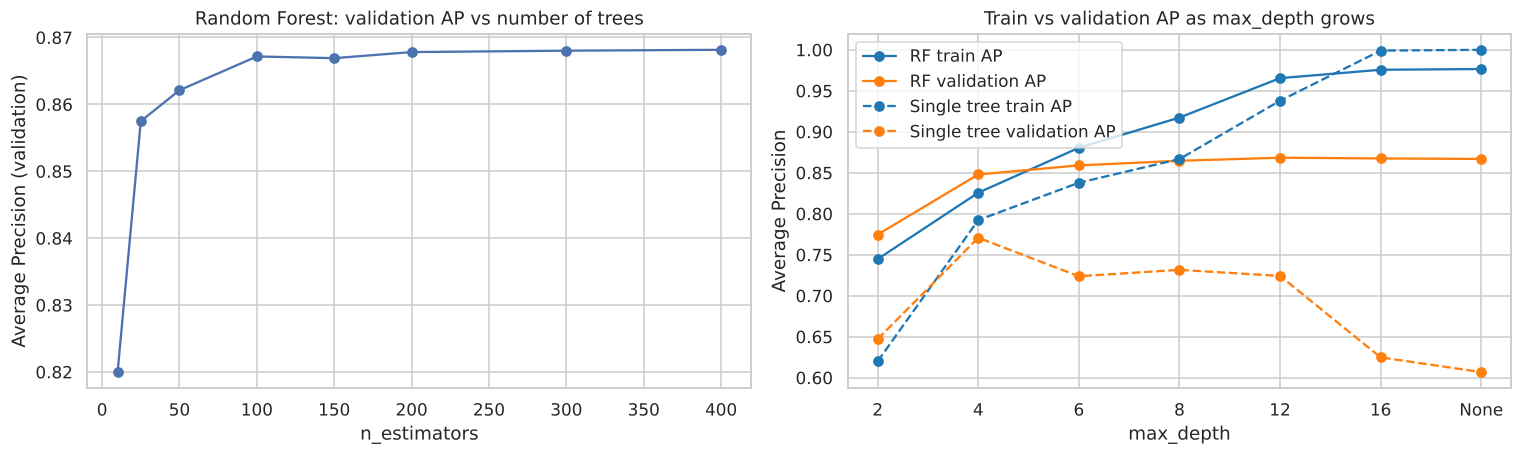

,RF train AP,RF validation AP,Single tree train AP,Single tree validation AP
depth,,,,
2,0.745,0.775,0.620,0.647
4,0.826,0.848,0.792,0.771
6,0.880,0.859,0.838,0.724
8,0.917,0.865,0.867,0.732
12,0.965,0.868,0.938,0.724
16,0.976,0.867,0.999,0.625
None,0.977,0.867,1.000,0.607


In [25]:
rf_best_params = {k: v for k, v in rf_search.best_params_.items() if k != "n_estimators"}

tree_counts = [10, 25, 50, 100, 150, 200, 300, 400]
growing_forest = RandomForestClassifier(max_samples=0.3, n_jobs=-1, random_state=SEED,
                                        warm_start=True, **rf_best_params)
curve_trees = []
for n in tree_counts:
    growing_forest.set_params(n_estimators=n)
    growing_forest.fit(X_train, y_train)
    curve_trees.append(average_precision_score(y_val, growing_forest.predict_proba(X_val)[:, 1]))

depths = [2, 4, 6, 8, 12, 16, None]
curve_depth = []
for d in depths:
    forest = RandomForestClassifier(n_estimators=150, max_samples=0.3, n_jobs=-1, random_state=SEED,
                                    **{**rf_best_params, "max_depth": d}).fit(X_train, y_train)
    tree = DecisionTreeClassifier(max_depth=d, random_state=SEED,
                                  min_samples_leaf=rf_best_params["min_samples_leaf"]).fit(X_train, y_train)
    curve_depth.append({"depth": "None" if d is None else str(d),
                        "RF train AP": average_precision_score(y_train, forest.predict_proba(X_train)[:, 1]),
                        "RF validation AP": average_precision_score(y_val, forest.predict_proba(X_val)[:, 1]),
                        "Single tree train AP": average_precision_score(y_train, tree.predict_proba(X_train)[:, 1]),
                        "Single tree validation AP": average_precision_score(y_val, tree.predict_proba(X_val)[:, 1])})
curve_depth = pd.DataFrame(curve_depth).set_index("depth")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
axes[0].plot(tree_counts, curve_trees, marker="o")
axes[0].set(title="Random Forest: validation AP vs number of trees", xlabel="n_estimators",
            ylabel="Average Precision (validation)")
curve_depth.plot(ax=axes[1], marker="o", style=["-", "-", "--", "--"],
                 color=["#1f77b4", "#ff7f0e", "#1f77b4", "#ff7f0e"])
axes[1].set(title="Train vs validation AP as max_depth grows", xlabel="max_depth", ylabel="Average Precision")
plt.tight_layout()
plt.show()
display(curve_depth.style.format("{:.3f}"))

### 10.2 Random Forest vs a single Decision Tree

The tuned single tree and the tuned forest are compared on the training and validation sets. For a single model, the **gap between training and validation** performance is a practical indicator of variance (overfitting). For a forest the training score is less informative: its fully grown trees have seen most training rows, so the in-sample score is always close to perfect. What matters is that the forest's **validation** score is higher and far more stable — see the depth plot above, where the single tree's validation AP collapses as depth grows while the forest's stays flat.

In [26]:
bias_variance_view = pd.DataFrame({
    name: {"train AP": average_precision_score(y_train, fraud_scores(board[name]["model"], X_train)),
           "validation AP": board[name]["val_ap"]}
    for name in ["Decision Tree", "Random Forest"]}).T
bias_variance_view["train - validation gap"] = bias_variance_view["train AP"] - bias_variance_view["validation AP"]
bias_variance_view.style.format("{:.3f}")

,train AP,validation AP,train - validation gap
Decision Tree,0.855,0.800,0.055
Random Forest,0.977,0.867,0.110


## 11. Boosting — Histogram-based Gradient Boosting

**Sequential learning.** Boosting builds an ensemble **one model at a time**. In gradient boosting each new shallow tree is fitted to the *gradient of the loss* — for log-loss this is essentially the gap between the true label and the current predicted probability. Transactions that are still misclassified therefore get the most attention from the next tree. The prediction is the sum of all trees, each shrunk by the `learning_rate`.

Where bagging mainly **reduces variance** by averaging independent strong learners, boosting mainly **reduces bias** by stacking many weak learners that correct one another — at the risk of overfitting if it runs for too many iterations or learns too fast.

**Implementation choice.** scikit-learn's `HistGradientBoostingClassifier` (inspired by LightGBM) bins each feature into at most 255 buckets, which makes it orders of magnitude faster than the classic `GradientBoostingClassifier` on 170 k rows, needs no extra installation and supports `class_weight`. Early stopping is disabled during tuning so that `max_iter` means exactly what the grid says.

**Tuned hyperparameters:** `learning_rate`, `max_iter` (number of boosting iterations), `max_leaf_nodes` (size of each tree), `l2_regularization`, `class_weight`.

In [27]:
hgb_search = run_search(
    HistGradientBoostingClassifier(early_stopping=False, random_state=SEED),
    {"learning_rate": [0.03, 0.06, 0.1],
     "max_iter": [200, 400],
     "max_leaf_nodes": [15, 31],
     "l2_regularization": [0.0, 1.0],
     "class_weight": [None, "balanced"]},
    n_iter=6, n_jobs=1)
register("Gradient Boosting (HGB)", hgb_search)

   search finished in 240s (6 configurations x 3 folds)


Gradient Boosting (HGB) CV AP = 0.841 ± 0.071 | val AP = 0.883 | val ROC-AUC = 0.981 | F2-threshold = 0.8911 | fit 18.0s
   best params: {'max_leaf_nodes': 31, 'max_iter': 400, 'learning_rate': 0.06, 'l2_regularization': 1.0, 'class_weight': 'balanced'}


### 11.1 Performance as boosting iterations increase

With `warm_start=True`, extra iterations are appended to the already-trained model, so we can trace training and validation AP after 25, 50, … iterations for three learning rates.

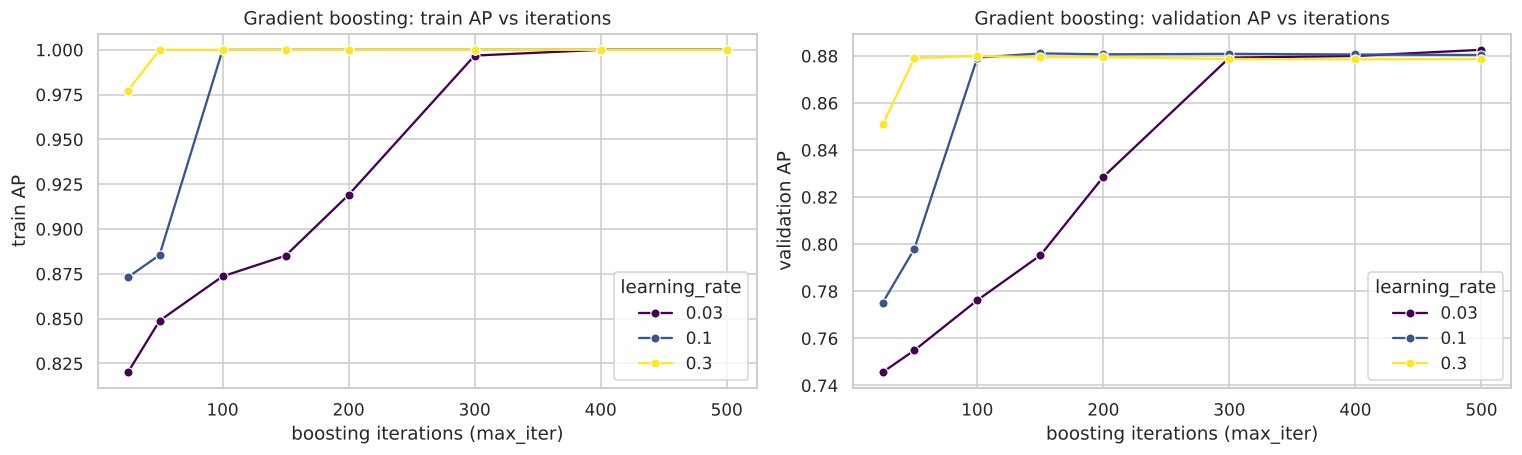

In [28]:
hgb_best = {k: v for k, v in hgb_search.best_params_.items() if k not in ("max_iter", "learning_rate")}
checkpoints = [25, 50, 100, 150, 200, 300, 400, 500]
iteration_curves = []
for lr in [0.03, 0.1, 0.3]:
    booster = HistGradientBoostingClassifier(learning_rate=lr, early_stopping=False, warm_start=True,
                                             random_state=SEED, **hgb_best)
    for n in checkpoints:
        booster.set_params(max_iter=n).fit(X_train, y_train)
        iteration_curves.append({"learning_rate": lr, "iterations": n,
                                 "train AP": average_precision_score(y_train, booster.predict_proba(X_train)[:, 1]),
                                 "validation AP": average_precision_score(y_val, booster.predict_proba(X_val)[:, 1])})
iteration_curves = pd.DataFrame(iteration_curves)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3), sharey=False)
for ax, metric in zip(axes, ["train AP", "validation AP"]):
    sns.lineplot(data=iteration_curves, x="iterations", y=metric, hue="learning_rate",
                 marker="o", palette="viridis", ax=ax)
    ax.set(title=f"Gradient boosting: {metric} vs iterations", xlabel="boosting iterations (max_iter)",
           ylabel=metric)
plt.tight_layout()
plt.show()

## 12. Stacking

### 12.1 Architecture

```
                    ┌──────────────────────────────┐
  training data ──▶ │ Level 0 (base learners)       │
                    │  • Logistic Regression (pipe) │  out-of-fold
                    │  • Decision Tree              │  fraud probabilities
                    │  • Random Forest              │ ───────────────┐
                    │  • Gradient Boosting (HGB)    │                │
                    └──────────────────────────────┘                ▼
                                                     ┌───────────────────────────┐
                                                     │ Level 1 (meta-learner)    │
                                                     │ Logistic Regression       │──▶ final fraud probability
                                                     └───────────────────────────┘
```

**How it avoids leakage.** `StackingClassifier(cv=3)` splits the training set into three folds. Each base learner is trained on two folds and predicts the third, so every training row receives a prediction from a model that **never saw that row** (out-of-fold predictions). The meta-learner is trained on these honest predictions. Afterwards each base learner is refitted on the full training set to produce the inputs for new data. Scaling and resampling remain inside each base learner's own pipeline, so they too are re-fitted fold by fold.

**Why these base learners.** They make different kinds of errors: a linear model (high bias, low variance), a single tree (low bias, high variance), a bagged forest and a boosted ensemble. Diversity is what gives the meta-learner something to combine. SVM and KNN are excluded from the stack only for computational reasons (they would have to be refitted four extra times and are slow to predict).

**Why Logistic Regression as meta-learner.** The meta-features are just four probabilities, which are highly correlated with each other. A simple, regularised linear model learns a weighted vote without overfitting them; a complex meta-learner would easily overfit the few hundred fraud rows.

In [29]:
stack = StackingClassifier(
    estimators=[("logreg", clone(board["Logistic Regression"]["model"])),
                ("tree", clone(board["Decision Tree"]["model"])),
                ("forest", clone(board["Random Forest"]["model"])),
                ("boost", clone(board["Gradient Boosting (HGB)"]["model"]))],
    final_estimator=LogisticRegression(max_iter=2000, C=1.0),
    stack_method="predict_proba",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED),
    n_jobs=1)

# Cross-validated performance of the whole stacking procedure (nested: 3 outer x 3 inner folds)
t0 = time.perf_counter()
stack_cv = cross_validate(stack, X_train, y_train, cv=CV, scoring=PRIMARY_SCORING, n_jobs=1)
print(f"Stacking CV finished in {time.perf_counter() - t0:.0f}s")

t0 = time.perf_counter()
stack.fit(X_train, y_train)
stack_fit_seconds = time.perf_counter() - t0
register("Stacking", model=stack, fit_seconds=stack_fit_seconds, cv_scores=stack_cv["test_score"])

meta = stack.final_estimator_
print("\nMeta-learner weights per base learner:",
      dict(zip([n for n, _ in stack.estimators], np.round(meta.coef_.ravel(), 3))))

Stacking CV finished in 280s


Stacking               CV AP = 0.835 ± 0.059 | val AP = 0.870 | val ROC-AUC = 0.980 | F2-threshold = 0.323 | fit 152.0s

Meta-learner weights per base learner: {'logreg': np.float64(2.468), 'tree': np.float64(3.205), 'forest': np.float64(3.06), 'boost': np.float64(4.64)}


## 13. Hyperparameter Tuning Summary

All searches used only the training set and 3-fold stratified CV with Average Precision as the objective. The table lists the selected values; the CV column is the mean ± standard deviation over the three folds.

In [30]:
tuning_table = pd.DataFrame({
    name: {"CV AP (mean ± std)": f"{r['cv_ap']:.3f} ± {r['cv_ap_std']:.3f}",
           "best hyperparameters": ", ".join(f"{k.replace('model__', '')}={v}" for k, v in r["params"].items())
                                   or "base learners = tuned models above"}
    for name, r in board.items()}).T
pd.set_option("display.max_colwidth", 200)
tuning_table

,CV AP (mean ± std),best hyperparameters
Decision Tree,0.737 ± 0.063,"class_weight=None, max_depth=8, min_samples_leaf=5"
Logistic Regression,0.737 ± 0.038,"C=1.0, class_weight=None"
SVM (RBF),0.700 ± 0.059,"C=0.1, gamma=0.001"
KNN,0.745 ± 0.053,"n_neighbors=35, weights=distance"
Random Forest,0.811 ± 0.059,"n_estimators=150, min_samples_leaf=1, max_features=sqrt, max_depth=None, class_weight=None"
Gradient Boosting (HGB),0.841 ± 0.071,"max_leaf_nodes=31, max_iter=400, learning_rate=0.06, l2_regularization=1.0, class_weight=balanced"
Stacking,0.835 ± 0.059,base learners = tuned models above


## 14. Model Evaluation and Comparison

### 14.1 Validation results and model selection

**Selection rule (decided before looking at the test set):** the deployed model is the one with the highest **validation Average Precision**. AP summarises precision across every possible threshold, so it measures how well a model puts fraud at the top of the alert queue — the property that matters regardless of how many alerts the fraud team can handle. The threshold is then set by the F2 rule from Section 9.1.

In [31]:
validation_table = pd.DataFrame({
    name: {"CV AP": r["cv_ap"], "val AP": r["val_ap"], "val ROC-AUC": r["val_roc"],
           "val F2 @ chosen threshold": r["val_f2"], "chosen threshold": r["threshold"]}
    for name, r in board.items()}).T.sort_values("val AP", ascending=False)
display(validation_table.style.format("{:.3f}", subset=["CV AP", "val AP", "val ROC-AUC",
                                                       "val F2 @ chosen threshold"])
        .format("{:.4g}", subset=["chosen threshold"])
        .background_gradient(cmap="Blues", subset=["val AP"]))

selected_model = validation_table.index[0]
print(f"Selected model (highest validation AP): {selected_model}")

,CV AP,val AP,val ROC-AUC,val F2 @ chosen threshold,chosen threshold
Gradient Boosting (HGB),0.841,0.883,0.981,0.882,0.8911
Stacking,0.835,0.870,0.980,0.880,0.323
Random Forest,0.811,0.867,0.956,0.879,0.24
KNN,0.745,0.802,0.955,0.851,0.362
Logistic Regression,0.737,0.801,0.975,0.830,0.05216
Decision Tree,0.737,0.800,0.942,0.864,0.5
SVM (RBF),0.700,0.759,0.980,0.810,0.8476


Selected model (highest validation AP): Gradient Boosting (HGB)


### 14.2 Final evaluation on the untouched test set

The test set is now used for the first and only time. Each model is applied with the threshold it received on the validation set. ROC-AUC and Average Precision are computed from the **continuous scores**, the other metrics from the thresholded decisions.

In [32]:
def test_metrics(name: str) -> dict:
    r = board[name]
    scores = fraud_scores(r["model"], X_test)
    pred = (scores >= r["threshold"]).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    r.update(test_scores=scores, test_pred=pred)
    return {"Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred),
            "F2": fbeta_score(y_test, pred, beta=2),
            "ROC-AUC": roc_auc_score(y_test, scores),
            "Average Precision": average_precision_score(y_test, scores),
            "Accuracy": accuracy_score(y_test, pred),
            "TP": tp, "FN": fn, "FP": fp, "TN": tn,
            "CV AP (train)": r["cv_ap"],
            "Training time (s)": r["fit_seconds"]}

model_order = list(board)                     # baselines first, then RF, boosting, stacking
results = pd.DataFrame({name: test_metrics(name) for name in model_order}).T
for c in ["TP", "FN", "FP", "TN"]:
    results[c] = results[c].astype(int)
results.insert(0, "Type", ["Baseline"] * 4 + ["Bagging", "Boosting", "Stacking"])

metric_cols = ["Precision", "Recall", "F1", "F2", "ROC-AUC", "Average Precision", "Accuracy", "CV AP (train)"]
(results.style.format("{:.3f}", subset=metric_cols)
        .format("{:.1f}", subset=["Training time (s)"])
        .highlight_max(subset=["Precision", "Recall", "F1", "F2", "ROC-AUC", "Average Precision"],
                       color="#c7e9c0"))

,Type,Precision,Recall,F1,F2,ROC-AUC,Average Precision,Accuracy,TP,FN,FP,TN,CV AP (train),Training time (s)
Decision Tree,Baseline,0.932,0.716,0.810,0.751,0.907,0.700,0.999,68,27,5,56646,0.737,5.8
Logistic Regression,Baseline,0.763,0.779,0.771,0.776,0.949,0.697,0.999,74,21,23,56628,0.737,0.3
SVM (RBF),Baseline,0.692,0.779,0.733,0.760,0.971,0.671,0.999,74,21,33,56618,0.700,1.7
KNN,Baseline,0.807,0.747,0.776,0.759,0.938,0.743,0.999,71,24,17,56634,0.745,0.1
Random Forest,Bagging,0.849,0.768,0.807,0.783,0.938,0.777,0.999,73,22,13,56638,0.811,26.2
Gradient Boosting (HGB),Boosting,0.948,0.768,0.849,0.799,0.965,0.827,1.000,73,22,4,56647,0.841,18.0
Stacking,Stacking,0.947,0.747,0.835,0.780,0.963,0.813,1.000,71,24,4,56647,0.835,152.0


For transparency, the next table shows the same models with the naive **default threshold** (0.5 for probabilities, 0 for the SVM decision function). Comparing it with the table above shows how much the threshold choice — not only the algorithm — drives precision and recall.

In [33]:
default_cut = {name: (0.0 if not hasattr(board[name]["model"], "predict_proba") else 0.5) for name in board}
default_table = pd.DataFrame({
    name: {"Precision@default": precision_score(y_test, board[name]["test_scores"] >= default_cut[name], zero_division=0),
           "Recall@default": recall_score(y_test, board[name]["test_scores"] >= default_cut[name]),
           "F1@default": f1_score(y_test, board[name]["test_scores"] >= default_cut[name])}
    for name in board}).T
default_table.style.format("{:.3f}")

,Precision@default,Recall@default,F1@default
Decision Tree,0.932,0.716,0.810
Logistic Regression,0.851,0.600,0.704
SVM (RBF),0.107,0.842,0.190
KNN,0.855,0.747,0.798
Random Forest,0.957,0.695,0.805
Gradient Boosting (HGB),0.936,0.768,0.844
Stacking,0.945,0.726,0.821


### 14.3 Confusion matrices (test set, validation-chosen thresholds)

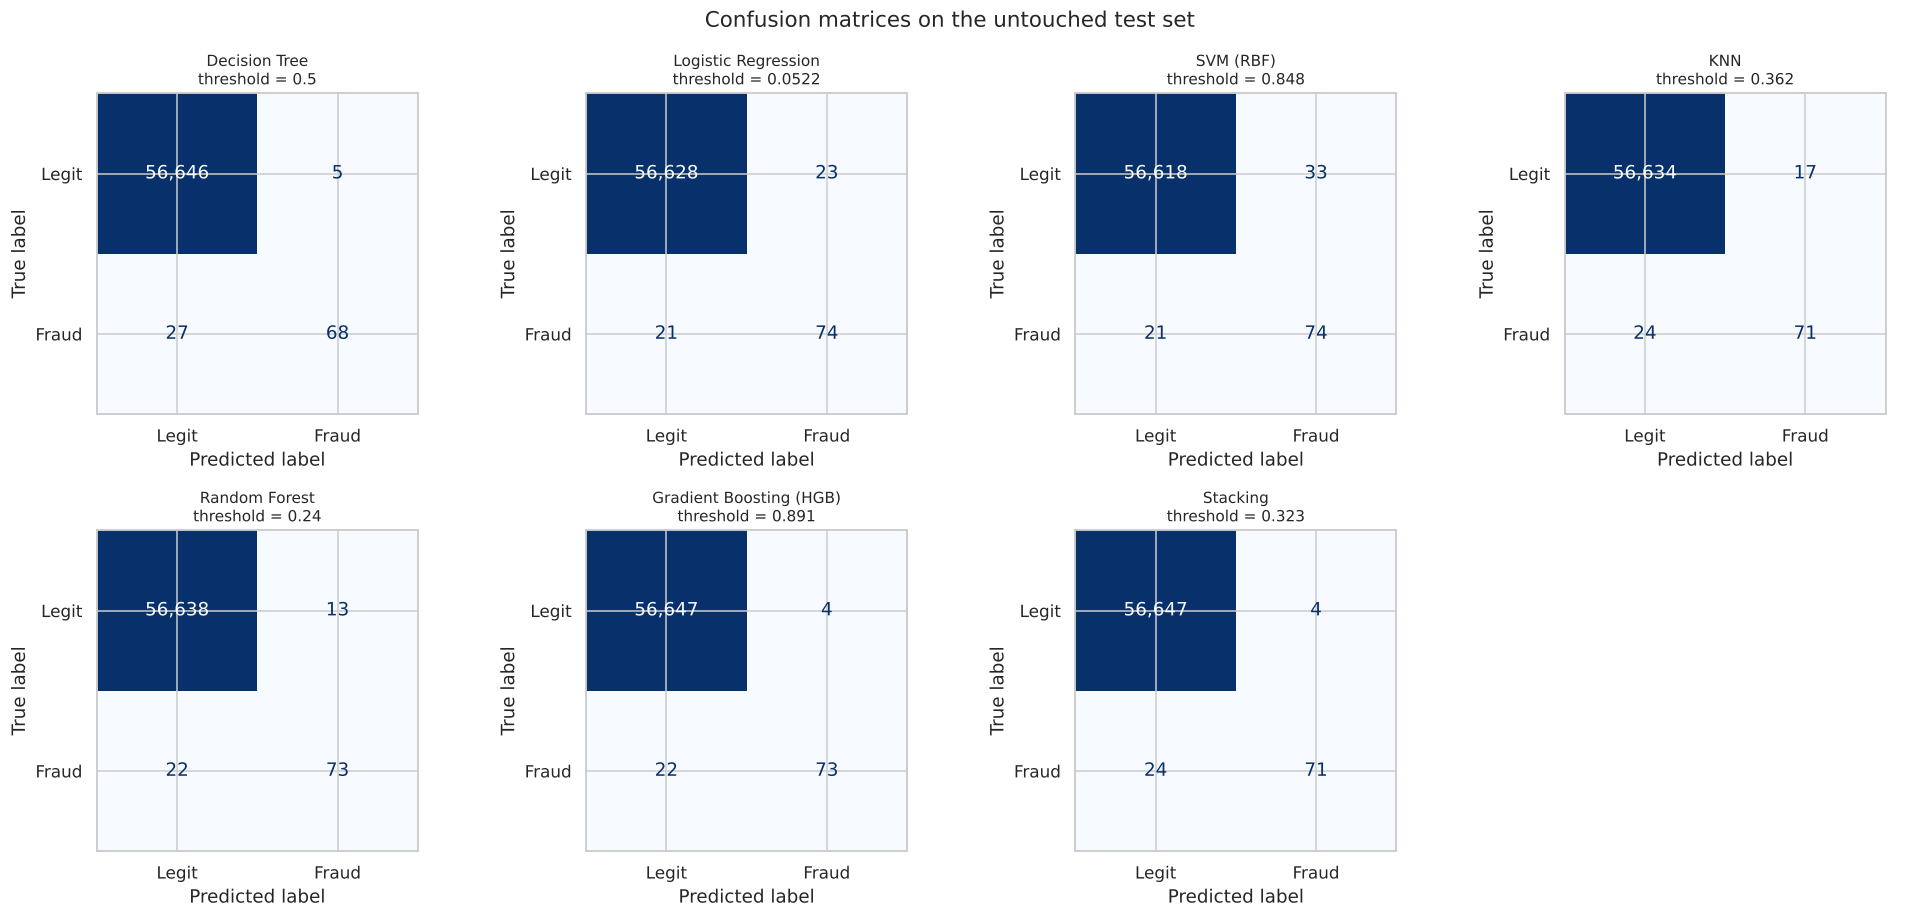

In [34]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8.5))
for ax, name in zip(axes.ravel(), model_order):
    ConfusionMatrixDisplay.from_predictions(y_test, board[name]["test_pred"], ax=ax, colorbar=False,
                                            display_labels=["Legit", "Fraud"], cmap="Blues",
                                            values_format=",d")
    ax.set_title(f"{name}\nthreshold = {board[name]['threshold']:.3g}", fontsize=10)
axes.ravel()[-1].axis("off")
plt.suptitle("Confusion matrices on the untouched test set", fontsize=14)
plt.tight_layout()
plt.show()

### 14.4 ROC and Precision–Recall curves (test set)

The ROC curve plots recall against the false-positive *rate*. With ~99.8 % legitimate transactions even a tiny FPR means many false alerts, so ROC curves look optimistic. The **Precision–Recall curve** shows directly what fraction of alerts are real fraud at each recall level and is therefore the more informative picture here. The dashed horizontal line is the precision of random guessing (the fraud rate).

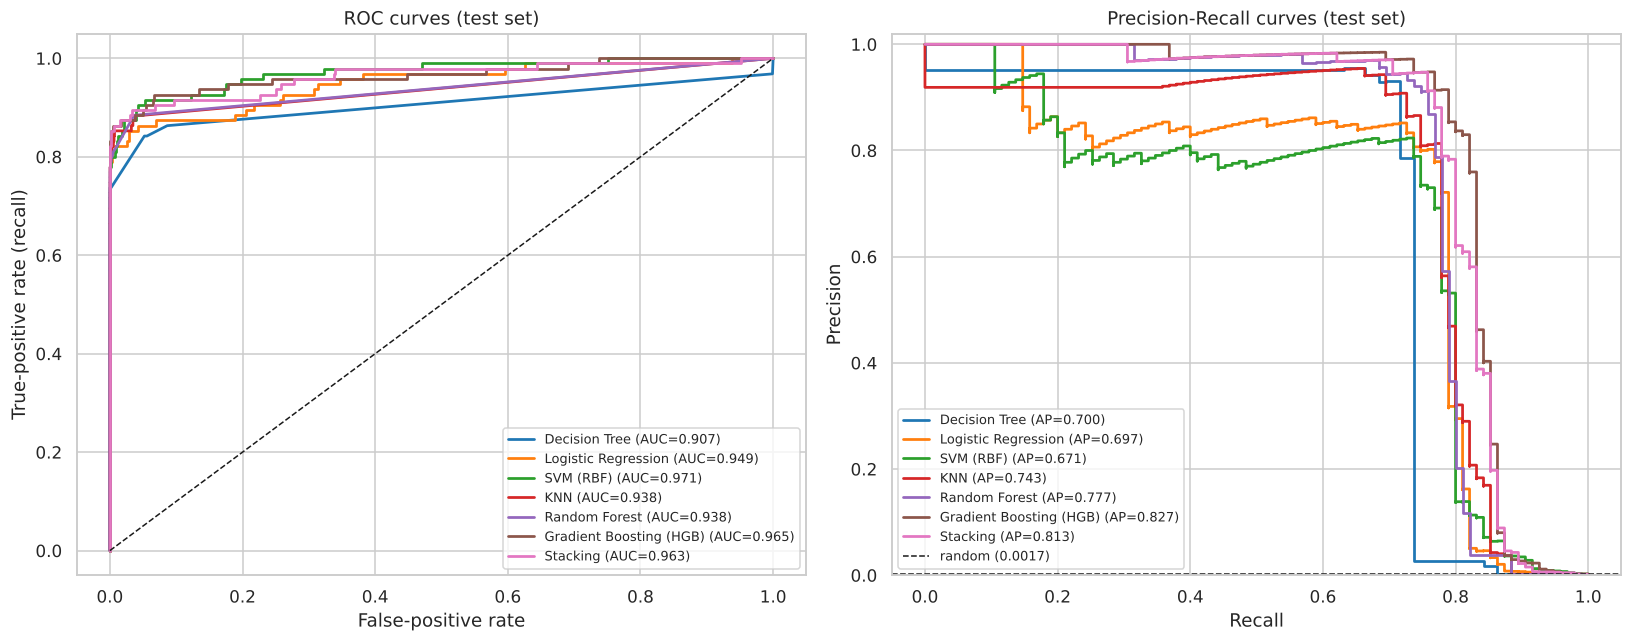

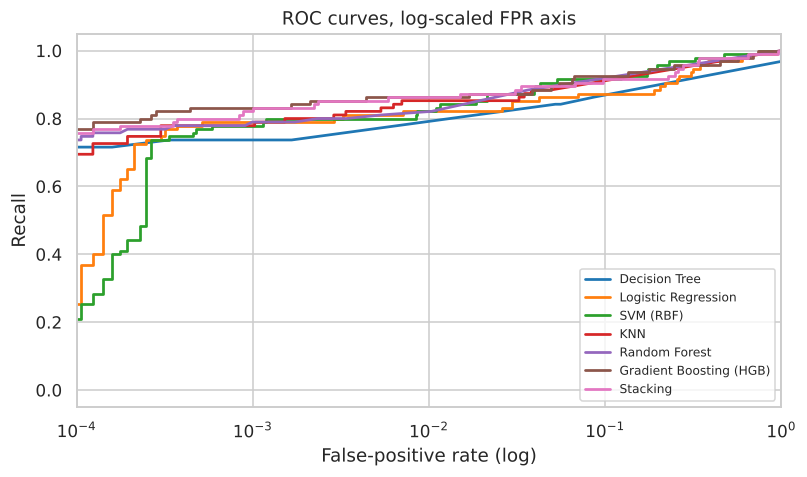

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
palette = sns.color_palette("tab10", len(model_order))
for color, name in zip(palette, model_order):
    s = board[name]["test_scores"]
    fpr, tpr, _ = roc_curve(y_test, s)
    axes[0].plot(fpr, tpr, color=color, lw=1.8, label=f"{name} (AUC={roc_auc_score(y_test, s):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, s)
    axes[1].step(rec, prec, where="post", color=color, lw=1.8,
                 label=f"{name} (AP={average_precision_score(y_test, s):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(title="ROC curves (test set)", xlabel="False-positive rate", ylabel="True-positive rate (recall)")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"random ({y_test.mean():.4f})")
axes[1].set(title="Precision-Recall curves (test set)", xlabel="Recall", ylabel="Precision", ylim=(0, 1.02))
for ax in axes:
    ax.legend(fontsize=8.5, loc="lower right" if ax is axes[0] else "lower left")
plt.tight_layout()
plt.show()

# Zoom on the low-FPR region, where real fraud systems operate
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for color, name in zip(palette, model_order):
    fpr, tpr, _ = roc_curve(y_test, board[name]["test_scores"])
    ax.plot(fpr, tpr, color=color, lw=1.8, label=name)
ax.set(xscale="log", xlim=(1e-4, 1), title="ROC curves, log-scaled FPR axis", xlabel="False-positive rate (log)",
       ylabel="Recall")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 14.5 Metric and training-time comparison charts

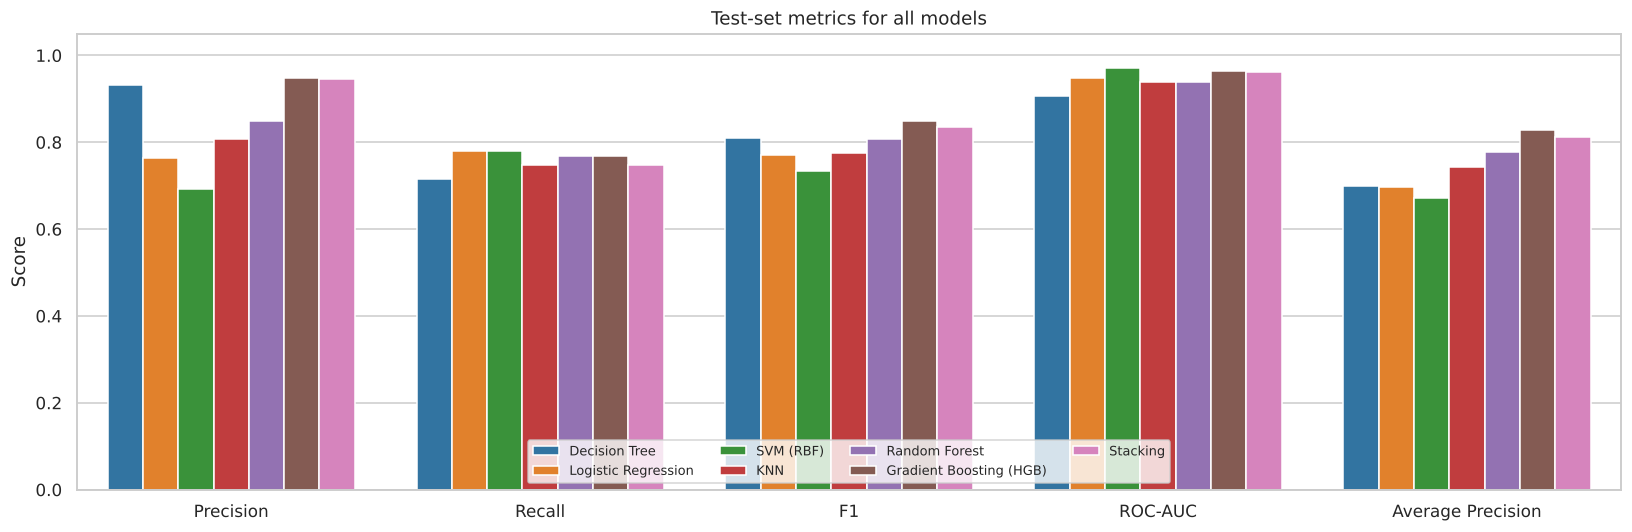

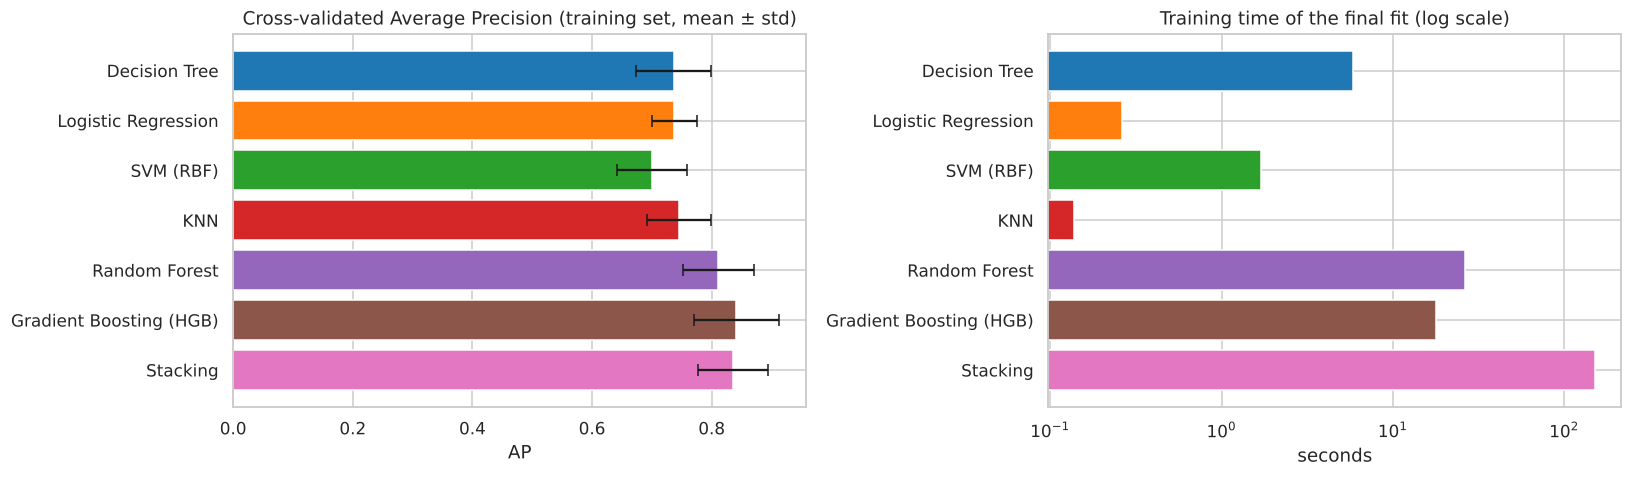

In [36]:
plot_metrics = ["Precision", "Recall", "F1", "ROC-AUC", "Average Precision"]
long = results[plot_metrics].reset_index(names="Model").melt(id_vars="Model", var_name="Metric", value_name="Score")

fig, ax = plt.subplots(figsize=(15, 5))
sns.barplot(data=long, x="Metric", y="Score", hue="Model", ax=ax, palette="tab10")
ax.set(title="Test-set metrics for all models", ylim=(0, 1.05), xlabel="")
ax.legend(ncol=4, fontsize=8.5, loc="lower center")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
cv_view = pd.DataFrame({"mean": [board[n]["cv_ap"] for n in model_order],
                        "std": [board[n]["cv_ap_std"] for n in model_order]}, index=model_order)
axes[0].barh(cv_view.index, cv_view["mean"], xerr=cv_view["std"], color=palette, capsize=4)
axes[0].set(title="Cross-validated Average Precision (training set, mean ± std)", xlabel="AP")
axes[0].invert_yaxis()
axes[1].barh(results.index, results["Training time (s)"], color=palette)
axes[1].set(xscale="log", title="Training time of the final fit (log scale)", xlabel="seconds")
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()

## 15. Visualisations of Model Behaviour and Feature Importance

### 15.1 Feature importance

Three complementary views:

* **Random Forest impurity importance** — how much each feature reduced Gini impurity, averaged over trees (fast, but biased toward features with many split points).
* **Permutation importance of the boosting model** on the *validation* set — how much Average Precision drops when one feature is randomly shuffled. This is model-agnostic and measured on unseen data.
* **Logistic Regression coefficients** (standardised features) — direction and strength of each feature's linear effect.

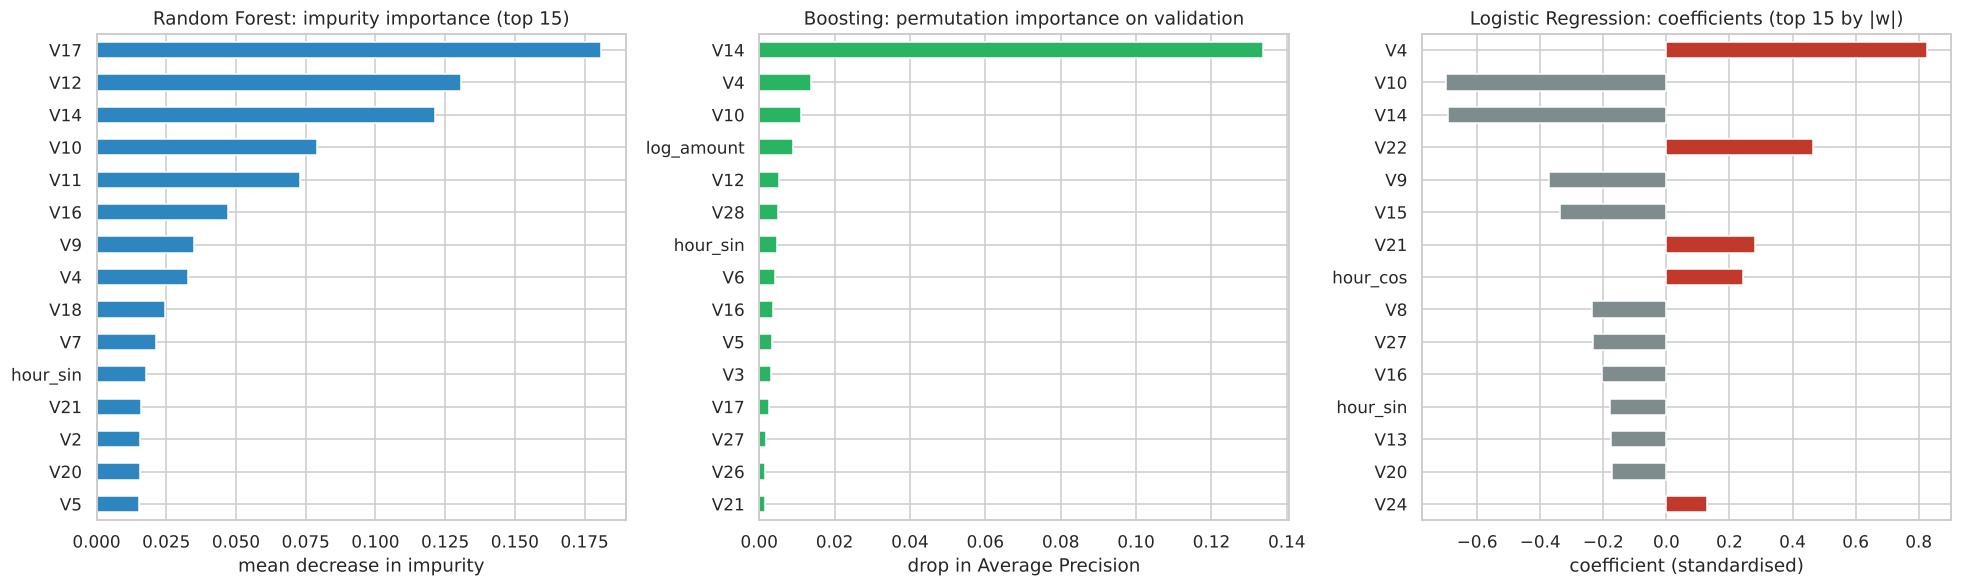

Features in the top-8 of both the RF and the permutation ranking: ['V10', 'V12', 'V14', 'V4']


In [37]:
rf_model = board["Random Forest"]["model"]
rf_imp = pd.Series(rf_model.feature_importances_, index=FEATURES).sort_values(ascending=False)

perm = permutation_importance(board["Gradient Boosting (HGB)"]["model"], X_val, y_val,
                              scoring="average_precision", n_repeats=3, random_state=SEED, n_jobs=1)
perm_imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False)

lr_model = board["Logistic Regression"]["model"]
lr_feature_names = [n.split("__")[-1] for n in lr_model.named_steps["scale"].get_feature_names_out()]
lr_coef = pd.Series(lr_model.named_steps["model"].coef_.ravel(), index=lr_feature_names)
lr_top = lr_coef.reindex(lr_coef.abs().sort_values(ascending=False).index[:15])

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
rf_imp.head(15)[::-1].plot.barh(ax=axes[0], color="#2e86c1")
axes[0].set(title="Random Forest: impurity importance (top 15)", xlabel="mean decrease in impurity")
perm_imp.head(15)[::-1].plot.barh(ax=axes[1], color="#28b463")
axes[1].set(title="Boosting: permutation importance on validation", xlabel="drop in Average Precision")
lr_top[::-1].plot.barh(ax=axes[2], color=np.where(lr_top[::-1] > 0, "#c0392b", "#7f8c8d"))
axes[2].set(title="Logistic Regression: coefficients (top 15 by |w|)", xlabel="coefficient (standardised)")
plt.tight_layout()
plt.show()

top_overlap = set(rf_imp.head(8).index) & set(perm_imp.head(8).index)
print("Features in the top-8 of both the RF and the permutation ranking:", sorted(top_overlap))

### 15.2 Choosing the operating threshold for the selected model

The plot shows how precision and recall of the selected model change with the threshold on the **validation set**, and the table translates thresholds into the number of alerts the fraud team would have to review. The chosen F2 threshold is marked.

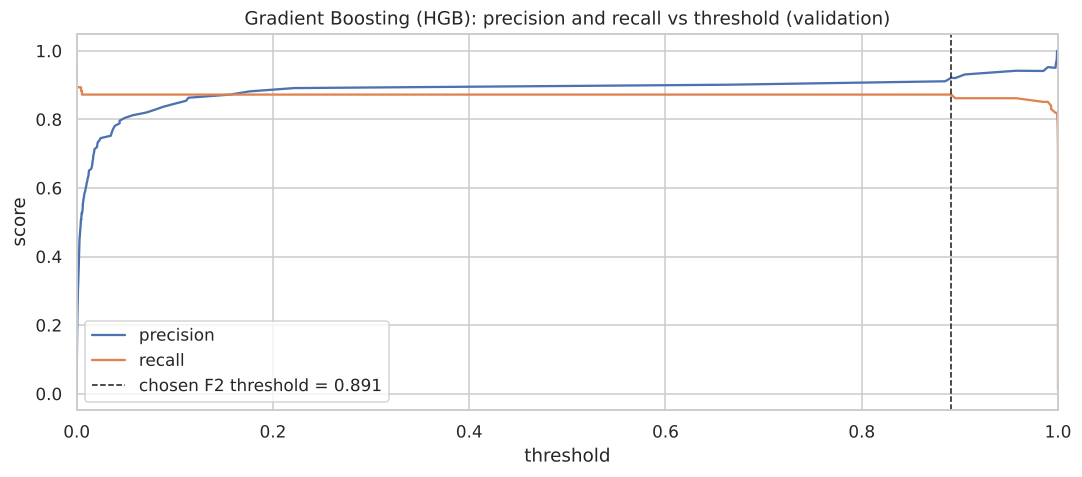

,threshold,alerts,alerts per 10k transactions,frauds caught,frauds missed,recall,precision
0,0.02,114,20.1,82,12,0.872,0.719
1,0.05,101,17.8,82,12,0.872,0.812
2,0.1,96,16.9,82,12,0.872,0.854
3,0.2,92,16.2,82,12,0.872,0.891
4,0.3,91,16.0,82,12,0.872,0.901
5,0.5,91,16.0,82,12,0.872,0.901
6,0.7,90,15.9,82,12,0.872,0.911
7,0.8911,89,15.7,82,12,0.872,0.921
8,0.9,87,15.3,81,13,0.862,0.931


In [38]:
sel = board[selected_model]
prec, rec, thr = precision_recall_curve(y_val, sel["val_scores"])

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(thr, prec[:-1], label="precision")
ax.plot(thr, rec[:-1], label="recall")
ax.axvline(sel["threshold"], color="k", ls="--", lw=1, label=f"chosen F2 threshold = {sel['threshold']:.3g}")
if hasattr(sel["model"], "predict_proba"):
    ax.set_xlim(0, 1)
ax.set(title=f"{selected_model}: precision and recall vs threshold (validation)", xlabel="threshold",
       ylabel="score")
ax.legend()
plt.tight_layout()
plt.show()

def alert_budget_table(y_true, scores, thresholds) -> pd.DataFrame:
    rows = []
    for t in thresholds:
        flagged = scores >= t
        caught = int((flagged & (y_true == 1)).sum())
        rows.append({"threshold": t, "alerts": int(flagged.sum()),
                     "alerts per 10k transactions": 1e4 * flagged.mean(),
                     "frauds caught": caught, "frauds missed": int((y_true == 1).sum() - caught),
                     "recall": caught / max((y_true == 1).sum(), 1),
                     "precision": caught / max(flagged.sum(), 1)})
    return pd.DataFrame(rows)

if hasattr(sel["model"], "predict_proba"):
    grid_t = sorted({0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9, round(sel["threshold"], 4)})
else:
    grid_t = sorted(set(np.quantile(sel["val_scores"], [0.99, 0.995, 0.998, 0.999])) | {sel["threshold"]})
alert_budget_table(y_val, sel["val_scores"], grid_t).style.format(
    {"threshold": "{:.4g}", "alerts per 10k transactions": "{:.1f}", "recall": "{:.3f}", "precision": "{:.3f}"})

### 15.3 Score distribution of the selected model

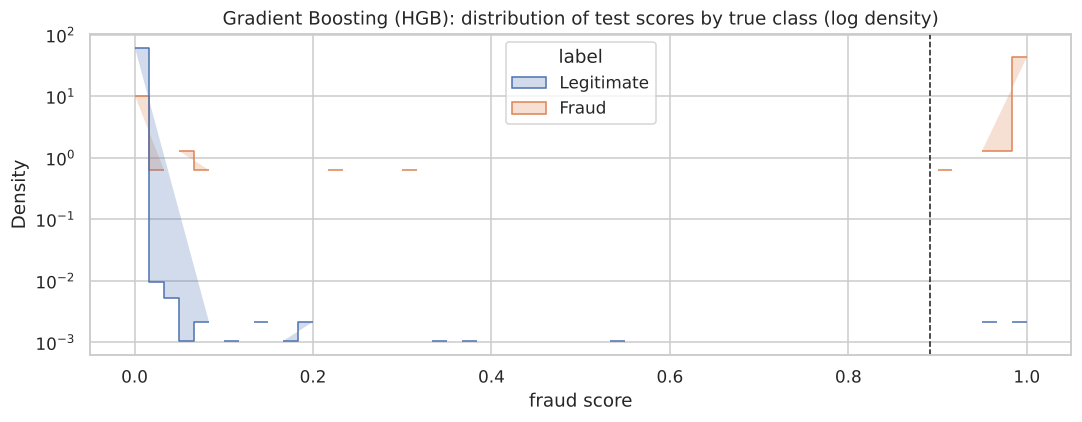

Frauds missed by Gradient Boosting (HGB) on the test set: 22 of 95


In [39]:
fig, ax = plt.subplots(figsize=(10, 4))
test_frame = pd.DataFrame({"score": sel["test_scores"], "label": np.where(y_test == 1, "Fraud", "Legitimate")})
sns.histplot(data=test_frame, x="score", hue="label", bins=60, stat="density", common_norm=False,
             element="step", ax=ax, log_scale=(False, True))
ax.axvline(sel["threshold"], color="k", ls="--", lw=1, label="chosen threshold")
ax.set(title=f"{selected_model}: distribution of test scores by true class (log density)", xlabel="fraud score")
plt.tight_layout()
plt.show()

missed = test_frame[(test_frame.label == "Fraud") & (test_frame.score < sel["threshold"])]
print(f"Frauds missed by {selected_model} on the test set: {len(missed)} of {int(y_test.sum())}")

## 16. Results Discussion and Interpretation

The numbers quoted below come from the executed run of this notebook (fixed seed 42). Training times depend on the machine; all other values should reproduce exactly with the same library versions. **Note on uncertainty:** the test set contains only 95 frauds, so one extra caught fraud changes recall by about one percentage point, and the cross-validation standard deviations (±0.04–0.07 AP) are larger than several of the gaps between models. Small differences should not be over-interpreted.

### 16.1 Which individual model performed best?

No baseline clearly dominated. On the validation set KNN, Logistic Regression and the Decision Tree were practically tied (AP ≈ 0.80); KNN had the best cross-validated AP (0.745) and the best test AP (0.743) among the baselines, so it is the **best individual model by the ranking metric**. The Decision Tree had the best test F1 (0.810) thanks to very few false alarms (5), but it missed the most frauds (27).

The SVM is an instructive case: it had the *highest* ROC-AUC of all baselines (0.971 on test) but the *lowest* Average Precision (0.671). Its scores separate the classes well overall, yet among its top-ranked transactions there are more legitimate ones. With 99.8 % legitimate traffic, ROC-AUC hides exactly this weakness — a concrete demonstration of why PR-AUC is the better primary metric here.

### 16.2 Which ensemble technique performed best?

**Boosting.** Histogram-based Gradient Boosting had the best CV AP (0.841), the best validation AP (0.883) and, on the untouched test set, the best Average Precision (0.827), F1 (0.849) and precision (0.948). At its validation-chosen threshold it caught 73 of 95 test frauds while raising only **4 false alarms among 56,651 legitimate transactions**. It was selected *before* looking at the test set, using validation AP, and the test results confirmed the choice.

### 16.3 Did bagging improve on a single Decision Tree?

Yes. Validation AP rose from 0.800 to 0.867 and test AP from 0.700 to 0.777; ROC-AUC rose from 0.907 to 0.938. At the chosen thresholds the forest caught five more test frauds (73 vs 68) at the cost of more alerts (13 vs 5), so F1 is similar (0.807 vs 0.810) — the gain is in the *ranking quality*, which lets the bank pick a better operating point. The depth experiment in Section 10.1 shows the mechanism: the single tree's validation AP peaks at depth 4 and then collapses to ~0.61 as it memorises the training data (train AP → 1.0), whereas the forest's validation AP keeps rising and then stays flat (~0.87) even with unlimited depth. That flat curve is variance reduction by averaging.

### 16.4 Did boosting outperform bagging?

Yes, on every threshold-free metric (test AP 0.827 vs 0.777, ROC-AUC 0.965 vs 0.938). Both caught the same 73 test frauds, but boosting needed far fewer false alarms (4 vs 13), i.e. its precision was much higher (0.948 vs 0.849). Boosting fits the residual structure of the hard, borderline transactions step by step, while the forest averages trees that each treat all rows alike.

### 16.5 Did stacking improve over its base models?

Partly. The stack (validation AP 0.870, test AP 0.813) beat three of its four base learners — Logistic Regression, the Decision Tree and the Random Forest — but **not** the boosting model it contained. The meta-learner gave the largest weight to the boosting model (coefficients: boosting 4.6, tree 3.2, forest 3.1, logistic 2.5), which shows it recognised the strongest learner, but it could not add much on top of it because:

* the base learners largely agree: all of them rank the obvious frauds at the top and all struggle with the same hard cases;
* with only ~280 training frauds, the meta-learner has little minority-class data to learn a better blend, and every weight it estimates adds variance;
* when one base model is clearly superior, stacking often converges to "mostly copy the best model".

Stacking was also by far the most expensive model (≈150 s to fit vs ≈18 s for boosting), so here it is not worth the extra complexity.

### 16.6 Why did the models perform differently?

* **Trees and tree ensembles** can carve out the small, oddly-shaped regions where fraud lives in the PCA space (e.g. very negative `V14` combined with other unusual components). Linear models can only draw one hyperplane.
* **Logistic Regression** still did well because a few components (`V14`, `V10`, `V4`, `V12`) separate the classes almost linearly; it is limited by its high bias.
* **SVM and KNN** were trained on an undersampled set (2 % ratio) for computational reasons. They saw only ~14 k of the 170 k legitimate transactions, which removes information about the legitimate class and explains part of their weaker precision.
* **Boosting** focuses its later trees on the transactions that are still misclassified — precisely the rare, borderline frauds that matter most.

### 16.7 Bias–variance interpretation

| Model | Bias | Variance | Evidence in this notebook |
|---|---|---|---|
| Logistic Regression | high | low | stable CV (±0.038, the lowest std) but limited AP |
| Deep Decision Tree | low | high | train AP 1.0 at full depth while validation AP falls to ~0.61 |
| Random Forest | low | reduced | averaging keeps validation AP ~0.87 at every depth ≥ 8 |
| Gradient Boosting | reduced step by step | controlled by learning rate / regularisation | train AP reaches ~1.0; validation AP plateaus at ~0.88 instead of dropping |
| Stacking | low | slightly higher than its best member | no gain over boosting with few minority samples |

The boosting curves (Section 11.1) show the classic learning-rate trade-off: with `learning_rate=0.3` the model reaches its best validation AP after only ~50 iterations, with `0.03` it needs ~300 iterations. Within 500 iterations none of them overfitted noticeably on validation, thanks to the L2 regularisation and limited leaf count.

### 16.8 Most influential features

The three importance methods agree on a small core: **`V14`, `V10`, `V12` and `V4`** appear near the top in the Random Forest ranking, the permutation ranking and the logistic coefficients; `V17` is the forest's top split feature. `V14` dominates the permutation importance of the boosting model — shuffling it alone costs ~0.13 AP. The engineered features (`log_amount`, `hour_sin`, `hour_cos`) contribute modestly. Because the `V` features are anonymised PCA components, we can say *which* components matter, but not what real-world behaviour they represent.

### 16.9 Computational cost

| Model | Final fit (s) | Notes |
|---|---|---|
| KNN / Logistic Regression / SVM | 0.1 – 1.7 | KNN and SVM are cheap to fit only because they use undersampled data; KNN and SVM are the slowest to *predict* |
| Decision Tree | ~6 | |
| Gradient Boosting (HGB) | ~18 | histogram binning makes it fast on 170 k rows |
| Random Forest | ~26 | with `max_samples=0.3`; tuning took ~4 min |
| Stacking | ~150 | 4 base learners × (3 folds + 1 refit); its nested CV alone took ~5 min |

Gradient boosting therefore offers the best accuracy per second of compute.

### 16.10 False negatives, false positives and the decision threshold

* **False negatives** are direct losses. The selected model still misses 22 of 95 test frauds. The score histogram (Section 15.3) shows why: these frauds receive *very low* scores — to the model they look like ordinary transactions. Lowering the threshold does not catch them: on the validation set, recall stays at 0.872 for every threshold between 0.02 and 0.89, while the number of alerts rises from 89 to 114.
* **False positives** cost analyst time and customer goodwill. At the chosen threshold the model raised about **16 alerts per 10,000 transactions**, and over 90 % of them were real fraud.
* The **F2 rule** placed the threshold at 0.89 — unusually high — because `class_weight="balanced"` pushes almost all fraud scores close to 1. The lesson is that a threshold is only meaningful together with the model that produced the scores; it must always be re-chosen on validation data when the model changes.
* For the business: if the fraud team can review more alerts, the threshold can be lowered with almost no loss of precision down to ~0.1, but the extra recall is negligible; catching the remaining frauds requires **new information** (e.g. customer history, merchant, device), not a different threshold.

### 16.11 Practical implications

* A gradient-boosted model with a validation-tuned threshold already detects about three quarters of fraud with very few false alerts, and it is cheap to train and fast to score — suitable for real-time use.
* Accuracy is useless for this decision: every model scored ≥ 99.9 % accuracy, including the ones with the weakest fraud detection.
* Class weighting and resampling mostly shift the default threshold (Section 8.1); with explicit threshold tuning their effect on ranking quality is small.

### 16.12 Limitations

* Only 473 unique frauds (95 in the test set) → wide uncertainty on recall and precision.
* Features are anonymised PCA components; no domain-driven feature engineering was possible.
* The data covers only two days, and the split is random rather than chronological, so the results probably overstate performance on future data (fraud patterns drift).
* SVM and KNN were trained on undersampled data and the hyperparameter grids were deliberately small to keep the run time reasonable.
* The F2 criterion is an assumption about relative costs; it does not use the actual transaction amounts.

### 16.13 Future work

* Time-based validation (train on earlier transactions, test on later ones) to measure drift.
* Cost-sensitive thresholding that weights each missed fraud by its `Amount` against a fixed review cost per alert.
* Probability calibration (`CalibratedClassifierCV`) so that scores can be read as real fraud probabilities.
* XGBoost / LightGBM / CatBoost and larger, Bayesian-optimised hyperparameter searches.
* Repeated stratified CV or bootstrap confidence intervals for the test metrics.

### 16.14 Cross-project discussion (fraud vs used-car price)

* **Different questions, different metrics.** Fraud detection is a *ranking-and-decision* problem with two very unequal classes, so it is judged by how well fraud is ranked (Average Precision, ROC-AUC) and by the counts of the two error types at a chosen threshold (precision, recall, confusion matrix). Price prediction outputs a continuous number, so it is judged by the *size* of the errors in money (MAE, RMSE) and by the share of variance explained (R²). There is no threshold to choose in regression.
* **Accuracy is misleading for fraud.** With ~99.83 % legitimate transactions, predicting "legitimate" for everything gives 99.83 % accuracy and catches nothing; in the fraud notebook every model scored ≥ 99.9 % accuracy even though their recall ranged from 0.72 to 0.78 and their false-alarm counts from 4 to 33.
* **MAE and RMSE are complementary.** MAE tells a seller the typical error (≈ 1.1–1.8 lakh here). RMSE squares the errors, so it is dominated by the few expensive cars with errors of 15–95 lakh; in the car notebook a single Range Rover changed the test RMSE ranking. Reporting both reveals whether a model is generally accurate *and* whether it occasionally makes very large mistakes.
* **Ensembles behaved differently in the two problems.** In fraud detection, boosting clearly won: it focuses later trees on the rare, hard positives, and tree ensembles are well suited to the non-linear, high-dimensional PCA features with 170 k training rows. In the car problem, the data set is small (~4 k training cars) with smooth, mostly monotone relationships on a log scale; here a kernel SVR was already excellent, and **stacking** — which leaned heavily on the SVR and gradient boosting — gave the best cross-validated and test results, while bagging and boosting gave similar, smaller gains over a single tree. Bagging improved on a single decision tree in **both** projects, confirming its value as a variance-reduction technique.
* **Why the winner differs.** Which ensemble helps most depends on what limits the base models: high variance (bagging helps), high bias or hard minority cases (boosting helps), or complementary error patterns across different model families (stacking helps). Data size, class balance, feature types and the evaluation metric all change which limitation dominates — so the best ensemble has to be found empirically for each data set, as done here.


## 17. Conclusion and Practical Recommendations

**Key findings**

* **Gradient Boosting (HGB)** was the best model before and after touching the test set: test Average Precision 0.827, ROC-AUC 0.965, precision 0.948 and recall 0.768 at the validation-chosen threshold — 73 of 95 frauds caught with only 4 false alarms among 56,651 legitimate test transactions.
* **Bagging** (Random Forest) clearly beat a single Decision Tree (test AP 0.777 vs 0.700) by reducing variance; **boosting** beat bagging (0.827 vs 0.777) by reducing bias on the hard cases; **stacking** (0.813) beat three of its four base learners but not the boosting model it contained, at ~8× the training cost.
* Accuracy (≥ 99.9 % for every model) says nothing about fraud detection. Average Precision and the precision/recall pair at an explicit threshold are the right tools.
* Class weighting and resampling mainly move the default threshold; choosing the threshold on validation data is the most direct way to control the trade-off between missed fraud and false alerts.

**Practical recommendations**

1. Deploy the gradient-boosting model with a threshold chosen on recent validation data according to the fraud team's alert capacity (here ~16 alerts per 10,000 transactions).
2. Re-tune the threshold whenever the model is retrained — thresholds are model-specific.
3. Monitor recall and precision over time and retrain on recent data, because fraud patterns drift.
4. To catch the ~23 % of fraud that currently looks completely normal, add new information sources (customer history, merchant, device) rather than lowering the threshold.

**Lessons learned:** on imbalanced data, the evaluation protocol (stratification, leakage-free pipelines, PR-based metrics, validation-based thresholds) matters as much as the choice of algorithm.

### Reproducibility note

This notebook was executed end-to-end, top to bottom, on a 2-CPU machine (total run time ≈ 30–35 minutes) with the library versions printed in Section 4. All tables, plots and numbers in the discussion come from that run.

## 18. References

1. Machine Learning Group – ULB. *Credit Card Fraud Detection* dataset. Kaggle. https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
2. Dal Pozzolo, A., Caelen, O., Johnson, R. A., & Bontempi, G. (2015). Calibrating Probability with Undersampling for Unbalanced Classification. *IEEE Symposium Series on Computational Intelligence*. (Dataset citation requested by the Kaggle page.)
3. scikit-learn: Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *JMLR* 12, 2825–2830. https://scikit-learn.org
4. scikit-learn User Guide — Ensembles (Random Forests, Gradient Boosting, Stacking): https://scikit-learn.org/stable/modules/ensemble.html
5. `DecisionTreeClassifier`: https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html
6. `LogisticRegression`: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
7. `SVC`: https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html
8. `KNeighborsClassifier`: https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html
9. `RandomForestClassifier`: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
10. `HistGradientBoostingClassifier`: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html
11. `StackingClassifier`: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingClassifier.html
12. Model evaluation (precision–recall, average precision, ROC): https://scikit-learn.org/stable/modules/model_evaluation.html
13. Permutation importance: https://scikit-learn.org/stable/modules/permutation_importance.html
14. imbalanced-learn documentation (SMOTE, RandomUnderSampler, Pipeline): https://imbalanced-learn.org/stable/
15. Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P. (2002). SMOTE: Synthetic Minority Over-sampling Technique. *Journal of Artificial Intelligence Research*, 16, 321–357.
16. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5–32.
17. Friedman, J. H. (2001). Greedy Function Approximation: A Gradient Boosting Machine. *Annals of Statistics*, 29(5), 1189–1232.
18. Wolpert, D. H. (1992). Stacked Generalization. *Neural Networks*, 5(2), 241–259.